# 04 — Visual retrieval (E5): ColQwen2 against OCR + BM25

**Objective.** Test whether a pretrained visual page retriever puts more annotated evidence in front of GPT-4o-mini than the application's OCR + BM25 retriever. The comparison counts the pages that **actually reach the model**: the top 5 after the application's context guard (3–4 pages at 768 px), not the raw top 5.

| | |
|---|---|
| **Specification** | `experiments/specs/e5_visual_retrieval_v1.json`, frozen in git before any visual score existed (this notebook refuses to run on an edited copy) |
| **Input** | `questions.parquet`, `pages.parquet`, `render_manifest_e1.csv` and the 768-px page images (00); `rankings.parquet`, `retrieval_per_question.csv` (01); the frozen E0 text run and E4 full run (regression references); 14 held-out MMLongBench-Doc PDFs (downloaded here, CC BY-NC 4.0, git-ignored); the checkpoint `vidore/colqwen2-v1.0-hf` at a pinned revision (downloaded once, 4.4 GB, git-ignored) |
| **Output** | `data/processed/mmlongbench_doc/e5/`: held-out page records and render manifest, rankings, per-question table, summary, encoding log, figures (regenerable); embeddings in `data/cache/e5/` (versioned by model revision and configuration); frozen copy in `experiments/frozen/e5/` |
| **Paid calls** | none. Nothing in this notebook calls an LLM or VLM API. |
| **Next** | If retrieval improves, a separate, paid end-to-end experiment (E6) with the same reader and request format; otherwise, the reader (`02`, `03`). |


## Method

### 1. Why test visual retrieval now

E4 showed that the application answers 11/40 answerable questions, against 17/37 for the same reader given the annotated evidence pages. Part of the gap is page selection. BM25's top 5 holds an evidence page for 32/40 questions, but the guard keeps only 3–4 pages, and those hold one for 29/40: 8 questions are not retrieved and 3 lose their rank-5 page to the guard. In a slide deck exported as images, BM25 depends on OCR, and a question about a chart or a photo may share few words with the page. A retriever that reads the **page image** might find such evidence. It might also put the evidence higher, which is what matters once only 3–4 pages survive the guard.

### 2. The visual retriever: ColQwen2 v1.0, a ColPali-family model

**ColPali** (Faysse et al., 2024, arXiv:2407.01449) treats a page as an image. The pipeline has no OCR and no layout parsing:

- **Encoder.** A vision-language model (PaliGemma-3B: SigLIP-So400m patch encoder + Gemma-2B) encodes the page, after a 448 × 448 resize, as 1,024 patch tokens plus a short prompt. Each output token is projected to $D = 128$ dimensions and L2-normalised.
- **Index.** A page is therefore a **bag of vectors** $\{d_j\}$, not one vector.
- **Query.** A query is encoded by the same language model as text tokens $\{q_i\}$, padded with a few augmentation tokens.
- **Score (late interaction, ColBERT's MaxSim).** Each query token finds its best-matching page token, and the matches are summed:

$$s(q, d) = \sum_{i=1}^{N_q} \max_{1 \le j \le N_d} \langle q_i, d_j \rangle .$$

- **Training.** One epoch of in-batch contrastive training with LoRA, on 118,695 English query–page pairs: 63 % from academic sets (DocVQA, InfoVQA, TAT-DQA, arXivQA), 37 % synthetic questions on web-crawled PDF pages.
- **Reported results.** On the ViDoRe benchmark (nDCG@5), ColPali scores 81.3 on average. BM25 on Unstructured + OCR text scores 65.5. The gap is largest on figures and tables (ArxivQA 79.1 vs 31.6) and smallest on text-heavy reports (AI 96.2 vs 92.8, TAT-DQA 65.8 vs 62.7).

**Why it might find what BM25 misses.**

- Page tokens carry layout, charts, logos and photographs, not only recognised words.
- A token can match a paraphrase or a visual concept, not just the same spelling.
- MaxSim lets each query word find its own region of the page.

**Costs and limits.**

- **Indexing.** It needs a 2–3B-parameter model run on every page: the paper reports 0.39 s per page on an NVIDIA L4.
- **Storage.** About 1,000 vectors × 128 × 2 bytes ≈ 250 KB per page, roughly 100× a BM25 posting list.
- **Scoring.** Cost grows with pages × query tokens × page tokens.
- **Training distribution.** English, mostly single pages.
- **Resolution.** A fixed 448-px square: a dense US-letter page loses detail, and its aspect ratio is distorted.

**ColVision models** keep the recipe (same authors, same training data, same MaxSim) and change the backbone:

- **ColQwen2 / ColQwen2.5** use Qwen2(.5)-VL, which encodes the page at its native aspect ratio with a variable number of tokens.
- **ColSmol** uses SmolVLM (256M/500M) for small devices.

**Choice for this experiment: `vidore/colqwen2-v1.0-hf`, revision `ddc07d23`.** It is **ColQwen2, not ColPali**, and is named so throughout. Four reasons:

1. **Same method and data as ColPali**, so the result tests the ColPali idea.
2. **Native aspect ratio**, up to 602,112 pixels (≤ 768 visual tokens). ColPali squeezes a page into 200,704 pixels.
3. **Fits this machine.** 2.2B parameters, a 4.4 GB checkpoint, Apache-2.0 licence. ColPali v1.3 is 2.9B parameters and 5.9 GB, on an 8 GB laptop.
4. **Runs on the installed library.** transformers 5.23.0 ships `ColQwen2ForRetrieval` and `ColQwen2Processor`, so no new framework is needed.

ColPali v1.3 itself is left untested. That is a limitation, not a substitution.

### 3. Design

- **Arm A: OCR + BM25.** The application's retriever, **unchanged**: notebook 00's text, notebook 01's BM25 ($k_1 = 1.5$, $b = 0.75$).
- **Arm V: ColQwen2 v1.0.** Page images (the application's own 768-px answering images) and MaxSim, with the processor's documented defaults.
- **Arm H: rank fusion (exploratory).** Reciprocal rank fusion $1/(60 + r_A) + 1/(60 + r_V)$. It is reported, never decided on.

Every arm is built the same way:

- **Input.** It ranks **every page of the question's PDF** from **the question string alone**, and returns 1-based physical page numbers. Evidence pages, answers, answer formats and sources are never passed to a ranking function (checked in section 6).
- **Context selection.** The same rule turns each ranking into the pages the model would receive. Take the top 5, then keep the longest prefix whose prompt fits $128{,}000 - 400$ tokens. For $S$ = kept pages and $q$ = the question,

$$100 + \text{bytes}(\text{system}) + \text{bytes}(\text{Question: } q \ldots) + \sum_{p \in S} \big(\text{bytes}(\texttt{[Page } p\texttt{]}) + \text{tok}(w_p, h_p)\big) \le 127{,}600,$$

where $\text{tok}(w, h) = 2{,}833 + 5{,}667 \times$ (512-px tiles after GPT-4o-mini's resizing). Section 4 checks this rule against the 57 page lists E4 actually sent.

### 4. Metrics

For annotated evidence pages $E$, supplied pages $S$ and retrieved top-$k$ pages $R_k$:

$$\text{Recall}_{\text{after}} = \frac{|E \cap S|}{|E|}, \qquad \text{Hit}_{\text{after}} = \mathbb 1\big[|E \cap S| > 0\big], \qquad \text{Complete}_{\text{after}} = \mathbb 1\big[E \subseteq S\big].$$

**Primary endpoint:** held-out mean $\text{Recall}_{\text{after}}$. **Key secondaries:** Hit and Complete.

**Secondary measures:**

- **Before the guard:** Recall@$k$ and Hit@$k$ for $k = 1, 3, 4, 5$.
- **Ranking quality:** MRR on the full ranking, $1/\min_{p \in E} \text{rank}(p)$, and binary nDCG@5, $\sum_{i \le 5} \text{rel}_i / \log_2(i+1)$ divided by its ideal value.
- **Context guard:** evidence lost to it.
- **Cost:** time, memory and storage.

### 5. Populations, statistics, decision rule (all frozen in the spec)

**Populations.**

- **Development** (6 documents, 57 questions, 40 in the evidence population). Earlier experiments chose the application's settings on it. It is used only for regression against the frozen BM25/E4 numbers and for diagnostics.
- **Held-out** (14 documents, 118 questions). Two documents per MMLongBench-Doc type, drawn by a seeded rule from documents this repository never touched, at most 100 pages each. The rule and its output were committed before any visual score existed.

**Statistics.**

- **Unit.** Each question is compared with itself across arms: $\Delta = \overline{m_V - m_A}$.
- **Clustering.** Questions cluster in documents, so the interval is a **document-cluster bootstrap**: 10,000 resamples of the documents, 95 % percentile.
- **Tests.** An exact document-level sign-flip test, and an exact McNemar test on Hit (descriptive, since it ignores clustering).
- **Variability.** Retrieval is deterministic, which is checked. The uncertainty is therefore sampling of documents and questions, not run-to-run noise, and E4's 5/37 reader-variability margin does not apply.

**Decision rule** (held-out, primary endpoint, $\delta = 0.05$):

| verdict | condition |
|---|---|
| **visual_improves_evidence** | all four hold: $\Delta \ge 0.05$; interval lower bound $> 0$; $\Delta_{\text{Hit}} \ge 0$; questions with less evidence under V $\le$ ½ × questions with more |
| **visual_worse** | $\Delta \le -0.05$ and interval upper bound $< 0$ |
| **no_meaningful_difference** | interval inside $(-0.05, 0.05)$ |
| **inconclusive** | anything else |

**Assumptions.** Evidence annotations are single, so another page may also contain the answer, which makes all recalls pessimistic for both arms. A hit is necessary but not sufficient for a correct answer.


In [1]:
from collections import Counter
from itertools import product
from math import ceil, comb, log, log2
from pathlib import Path
from types import SimpleNamespace
import ast
import gc
import hashlib
import io
import json
import os
import platform
import re
import shutil
import subprocess
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import pymupdf
from IPython.display import Markdown, display

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 170)


def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not find the repository root")


PROJECT_ROOT = find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "mmlongbench_doc"
E5_DIR = PROCESSED_DIR / "e5"
MMLONG_DIR = PROJECT_ROOT / "data" / "external" / "mmlongbench_doc"
PDF_DIR = MMLONG_DIR / "documents"
TESSDATA_DIR = PROJECT_ROOT / "resources" / "tessdata"
IMAGE_DIR = PROJECT_ROOT / "data" / "cache" / "mmlongbench_doc" / "page_images" / "short768-long1536"  # E1's 768-px profile
SPEC_PATH = PROJECT_ROOT / "experiments" / "specs" / "e5_visual_retrieval_v1.json"
FROZEN_E0_TEXT_RUN = PROJECT_ROOT / "experiments" / "frozen" / "mmlongbench_doc" / "text_run_20261119T220858Z_a351a532"
FROZEN_E4_RUN = PROJECT_ROOT / "experiments" / "frozen" / "e4" / "run_20261123T000625940289Z_15119ec0_full"
FROZEN_E5_DIR = PROJECT_ROOT / "experiments" / "frozen" / "e5"
E5_DIR.mkdir(parents=True, exist_ok=True)

# The spec was committed before any visual score existed. Evaluation refuses an edited copy: a change is a new version.
spec_relative = str(SPEC_PATH.relative_to(PROJECT_ROOT))
git = lambda *args: subprocess.run(["git", *args], cwd=PROJECT_ROOT, capture_output=True, check=True).stdout
freeze_commits = git("log", "--format=%H", "--diff-filter=A", "--", spec_relative).decode().split()
assert freeze_commits, f"{spec_relative} is not committed: freeze the spec before evaluating"
SPEC_FREEZE_COMMIT = freeze_commits[-1]
assert git("show", f"{SPEC_FREEZE_COMMIT}:{spec_relative}") == SPEC_PATH.read_bytes(), \
    "the E5 spec differs from its frozen commit; any change is a new spec version (e5-visual-retrieval-v2)"
SPEC = json.loads(SPEC_PATH.read_text())
assert SPEC["spec_id"] == "e5-visual-retrieval-v1" and SPEC["status"] == "frozen-before-evaluation"

SETTINGS = {
    "dataset_repo": "yubo2333/MMLongBench-Doc",
    "dataset_revision": "2ff6aa9237fc777b6627dc57a486e9225ac5fb86",
    "ocr_min_native_words": 30, "ocr_dpi": 150,                     # notebook 00
    "bm25_k1": 1.5, "bm25_b": 0.75, "top_k": 5,                    # notebook 01 / the application
    "image_short_px": 768, "image_long_px": 1536,                  # E1 profile = the application's answering images
    "heldout_seed": 20261123, "heldout_per_type": 2, "heldout_max_pages": 100, "heldout_max_mb": 15.0,
    "spot_check_n": 8,
    "k_values": [1, 3, 4, 5], "rrf_k": 60,
    "bootstrap_resamples": 10_000, "stat_seed": 20261123,
    "min_meaningful_difference": SPEC["hypotheses"]["minimum_meaningful_difference"],
}
assert SETTINGS["dataset_revision"] in SPEC["populations"]["held_out"]["source"]
assert str(SETTINGS["heldout_seed"]) in SPEC["populations"]["held_out"]["selection_rule"]
print(f"Spec {SPEC['spec_id']} frozen in commit {SPEC_FREEZE_COMMIT[:7]} at {SPEC['frozen_at']}; the file on disk equals it.")
print("Paid API calls in this notebook:", SPEC["paid_api_calls"])


Spec e5-visual-retrieval-v1 frozen in commit 073d0a4 at 2026-11-23T11:38:00Z; the file on disk equals it.
Paid API calls in this notebook: none: E5 is offline. No LLM or VLM API is called; the visual retriever runs locally.


## 1. Environment and resource feasibility

Before loading 2.2 billion parameters on a laptop, the cell below checks what the machine has and estimates what the model needs. It uses the **safetensors header** (tensor names and shapes, read without loading any weights) and the token counts of the pre-freeze probe.

**Measured before the spec was frozen** (three development pages, recorded in the spec):

- The full model in bf16 on MPS holds about 5.5 GB of GPU memory on this 8 GB M1 and runs at **35–45 s per page**, with the system swapping. Queries take 0.2 s. The cost is all in the 675M-parameter vision tower, which reads ~3,000 image patches.
- Running the two halves **in two passes** removes the memory contention and gives **~9.5 s (vision) + ~3.7 s (language model) per page**. Pass 1 runs only the vision tower over every page and caches its output. Pass 2 runs the library's own forward with the vision tower replaced by a stub that returns the cached output.
- The two passes do **identical arithmetic**: their embeddings were bitwise equal to the single-pass forward on all three pages. Section 5 checks this again.


In [2]:
import torch
import transformers
from safetensors import safe_open
from safetensors.torch import load_file, save as safetensors_bytes

MODEL = SPEC["arms"]["V_colqwen2"]["checkpoint"]
MODEL_DIR = PROJECT_ROOT / "data" / "cache" / "hf" / f"{MODEL['repo'].split('/')[-1]}@{MODEL['revision'][:12]}"
WEIGHTS = MODEL_DIR / MODEL["weights_file"]


def sha256_file(path, chunk=1 << 24):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        while block := handle.read(chunk):
            digest.update(block)
    return digest.hexdigest()


def temporary_path(path):
    # Hidden name in the same folder (same filesystem, so the rename is atomic); never matches "*.safetensors" or "page_*.png".
    return path.with_name(f".{path.name}.{os.getpid()}.tmp")


def atomic_write_bytes(path, data):
    # Write a temporary file, flush it to disk, then rename it over the target. os.replace is atomic: after an
    # interruption the target is either absent, its previous version or the complete new file, never a partial one.
    path = Path(path)
    temporary = temporary_path(path)
    with open(temporary, "wb") as handle:
        handle.write(data)
        handle.flush()
        os.fsync(handle.fileno())
    os.replace(temporary, path)


def atomic_save_tensors(tensors, path):
    # The bytes save_file(tensors, path) would write, written atomically.
    atomic_write_bytes(path, safetensors_bytes(tensors))


def remove_stale_temporaries(folder):
    # Temporary files left by an interrupted write; the targets they were meant to replace are untouched.
    stale = list(Path(folder).glob(".*.tmp"))
    for path in stale:
        path.unlink()
    return len(stale)


memory, disk = psutil.virtual_memory(), shutil.disk_usage(PROJECT_ROOT)
cpu = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True, text=True).stdout.strip() if sys.platform == "darwin" else platform.processor()
ENVIRONMENT = {
    "platform": f"{platform.system()} {platform.mac_ver()[0] or platform.release()} {platform.machine()}", "cpu": cpu,
    "cpu_cores": psutil.cpu_count(), "ram_gb": round(memory.total / 1e9, 1), "ram_available_gb_now": round(memory.available / 1e9, 1),
    "disk_free_gb_now": round(disk.free / 1e9, 1), "python": sys.version.split()[0], "torch": torch.__version__,
    "transformers": transformers.__version__, "pymupdf": pymupdf.VersionBind, "mps_available": torch.backends.mps.is_available(),
    "cuda_available": torch.cuda.is_available(),
}
display(pd.Series(ENVIRONMENT, name="value").to_frame())
assert transformers.__version__ == "5.23.0" and torch.__version__.startswith("2.15.0"), "versions differ from the spec: a new condition"
assert ENVIRONMENT["mps_available"], "the spec fixes the Apple MPS device; no fallback is pre-authorised (see the spec)"

# Download the pinned checkpoint once (4.4 GB, free, git-ignored), then verify its bytes against the spec.
if not WEIGHTS.is_file():
    assert disk.free > 8e9, f"downloading the checkpoint needs about 4.5 GB; only {disk.free / 1e9:.1f} GB free"
    from huggingface_hub import snapshot_download
    snapshot_download(MODEL["repo"], revision=MODEL["revision"], local_dir=MODEL_DIR)
weights_check_path = E5_DIR / "weights_check.json"
stat = WEIGHTS.stat()
check = json.loads(weights_check_path.read_text()) if weights_check_path.is_file() else {}
if check.get("size") != stat.st_size or check.get("mtime_ns") != stat.st_mtime_ns:  # hash once per file version (~1 min)
    check = {"size": stat.st_size, "mtime_ns": stat.st_mtime_ns, "sha256": sha256_file(WEIGHTS)}
    atomic_write_bytes(weights_check_path, json.dumps(check).encode())
assert check["size"] == MODEL["weights_bytes"] and check["sha256"] == MODEL["weights_sha256"], "checkpoint bytes differ from the spec"

# What each pass must hold in memory, from the safetensors header (no weights loaded).
with safe_open(WEIGHTS, framework="pt") as weights:
    tensor_sizes = {name: int(np.prod(weights.get_slice(name).get_shape())) for name in weights.keys()}
vision_params = sum(n for name, n in tensor_sizes.items() if ".visual." in name)
total_params = sum(tensor_sizes.values())
assert total_params == MODEL["parameters"]
n_dev_pages, n_heldout_pages = 195, SPEC["populations"]["held_out"]["size_at_selection"]["pages"]
tokens_per_page = 760  # 731-779 tokens on the three probe pages (<= 768 visual tokens + prompt)
estimates = pd.Series({
    "parameters, total": f"{total_params / 1e9:.2f} B ({total_params * 2 / 1e9:.2f} GB in bf16)",
    "pass 1: vision tower": f"{vision_params / 1e6:.0f} M parameters, {vision_params * 2 / 1e9:.2f} GB",
    "pass 2: language model + projection": f"{(total_params - vision_params) / 1e9:.2f} B parameters, {(total_params - vision_params) * 2 / 1e9:.2f} GB",
    "pages to encode (dev + held-out)": f"{n_dev_pages} + {n_heldout_pages} = {n_dev_pages + n_heldout_pages}",
    "embedding storage": f"~{tokens_per_page} x 128 x 2 bytes = {tokens_per_page * 256 / 1e3:.0f} KB per page, ~{(n_dev_pages + n_heldout_pages) * tokens_per_page * 256 / 1e6:.0f} MB in all",
    "temporary vision features": f"~744 x 1536 x 2 bytes = 2.3 MB per page, ~{(n_dev_pages + n_heldout_pages) * 2.3 / 1e3:.1f} GB until pass 2 consumes them",
    "time (probe: ~13 s per page)": f"~{(n_dev_pages + n_heldout_pages) * 13 / 3600:.1f} h for an empty cache; minutes when cached",
}, name="estimate").to_frame()
display(estimates)
assert disk.free > 3e9 or (E5_DIR / "encoding_log.csv").is_file(), "need ~3 GB free disk for temporary features and embeddings"
print(f"Checkpoint verified: {WEIGHTS.relative_to(PROJECT_ROOT)}, {check['size']:,} bytes, sha256 {check['sha256'][:12]}… = spec.")


,value
platform,Darwin 26.5.2 arm64
cpu,Apple M1
cpu_cores,8
ram_gb,8.6
ram_available_gb_now,3.1
disk_free_gb_now,11.6
python,3.12.6
torch,2.15.0
transformers,5.23.0
pymupdf,2.1


,estimate
"parameters, total",2.21 B (4.42 GB in bf16)
pass 1: vision tower,"665 M parameters, 1.33 GB"
pass 2: language model + projection,"1.54 B parameters, 3.09 GB"
pages to encode (dev + held-out),195 + 647 = 842
embedding storage,"~760 x 128 x 2 bytes = 195 KB per page, ~164 MB in all"
temporary vision features,"~744 x 1536 x 2 bytes = 2.3 MB per page, ~1.9 GB until p..."
time (probe: ~13 s per page),~3.0 h for an empty cache; minutes when cached


Checkpoint verified: data/cache/hf/colqwen2-v1.0-hf@ddc07d2317c8/model.safetensors, 4,418,454,832 bytes, sha256 2f6dbf32fc2d… = spec.


## 2. Dataset preparation and validation

**Development set.** It is read from notebooks 00 and 01 without change: 6 documents, 57 questions, and notebook 01's evidence population of 40 answerable questions.

**Held-out set.** The spec's rule is re-executed here, and its output must equal the document list committed in the spec. The rule:

- Exclude the 6 development documents and the four other MMLongBench-Doc documents named anywhere in this repository.
- Keep documents of at most 15 MB.
- For each of the 7 document types, in sorted order, permute the type's eligible documents with one shared seeded generator.
- Accept documents in that order if they have 1–100 pages, until 2 are accepted per type.

The rule reads only document metadata (type, size, page count), never a question, answer or retrieval result.

**Evidence population** (same definition for both sets): answerable questions with at least one evidence page, no page 0 and every evidence page inside the PDF. Rows excluded by each condition are counted.


In [3]:
for name in ("questions.parquet", "pages.parquet", "rankings.parquet", "retrieval_per_question.csv", "render_manifest_e1.csv"):
    assert (PROCESSED_DIR / name).is_file(), f"{name} is missing: run notebooks 00 and 01 first"
for path in (FROZEN_E0_TEXT_RUN / "scored_predictions.csv", FROZEN_E4_RUN / "execution_log.jsonl"):
    assert path.is_file(), f"{path.relative_to(PROJECT_ROOT)} is missing: restore experiments/frozen/ from git"

bench = pd.read_parquet(PROCESSED_DIR / "questions.parquet")  # the full benchmark table at the pinned revision (00)
for column in ("evidence_pages", "evidence_sources"):
    bench[column] = bench[column].map(list)
assert len(bench) == 1091 and bench["qid"].is_unique


def evidence_population(questions, page_counts):
    # The retrieval population of notebook 01, with the reason each other row is excluded.
    reasons = pd.DataFrame({
        "unanswerable": ~questions["answerable"],
        "no evidence page": questions["answerable"] & (questions["n_evidence_pages"] == 0),
        "cites page 0": questions["evidence_pages"].map(lambda e: 0 in e),
        "page beyond the PDF": [max(e, default=0) > page_counts[d] for e, d in zip(questions["evidence_pages"], questions["doc_id"])],
    }, index=questions.index)
    return questions[~reasons.any(axis=1)].copy(), reasons.sum().astype(int)


dev_q = bench[bench["in_subset"]].reset_index(drop=True)
dev_pages = pd.read_parquet(PROCESSED_DIR / "pages.parquet")
DEV_DOCS = sorted(dev_q["doc_id"].unique())
dev_page_count = dev_pages.groupby("doc_id")["page"].max()
dev_pop, dev_excluded = evidence_population(dev_q, dev_page_count)
assert len(dev_q) == 57 and len(dev_pages) == 195 and len(DEV_DOCS) == 6
assert set(dev_pop["qid"]) == set(pd.read_csv(PROCESSED_DIR / "retrieval_per_question.csv")["qid"]) and len(dev_pop) == 40
print(f"Development: {len(dev_q)} questions, {len(dev_pages)} pages, {len(DEV_DOCS)} documents; evidence population "
      f"{len(dev_pop)} (= notebook 01). Excluded rows: {dev_excluded[dev_excluded > 0].to_dict()}")


Development: 57 questions, 195 pages, 6 documents; evidence population 40 (= notebook 01). Excluded rows: {'unanswerable': 17}


In [4]:
from huggingface_hub import HfApi, hf_hub_download

HELD_OUT_SPEC = SPEC["populations"]["held_out"]
OTHER_TOUCHED = ["05-03-18-political-release.pdf", "2312.04350v3.pdf", "PH_2016.06.08_Economy-Final.pdf", "RAR.pdf"]
assert all(name in " ".join(HELD_OUT_SPEC["exclusions"]) for name in OTHER_TOUCHED)
EXCLUDED_DOCS = set(DEV_DOCS) | set(OTHER_TOUCHED)

hub_files = HfApi().list_repo_tree(SETTINGS["dataset_repo"], path_in_repo="documents", repo_type="dataset", revision=SETTINGS["dataset_revision"])
hub_mb = {Path(item.path).name: item.size / 1e6 for item in hub_files if item.path.endswith(".pdf")}
doc_type = bench.groupby("doc_id")["doc_type"].first()
assert set(doc_type.index) <= set(hub_mb)


def download_pdf(doc_id):
    return Path(hf_hub_download(SETTINGS["dataset_repo"], f"documents/{doc_id}", repo_type="dataset",
                                revision=SETTINGS["dataset_revision"], local_dir=MMLONG_DIR))


def pdf_page_count(path):
    with pymupdf.open(path) as pdf:
        return pdf.page_count


rng = np.random.default_rng(SETTINGS["heldout_seed"])  # one generator, shared across the types in sorted order
selection_log = []
for kind in sorted(doc_type.unique()):
    eligible = sorted(d for d in doc_type[doc_type == kind].index if d not in EXCLUDED_DOCS and hub_mb[d] <= SETTINGS["heldout_max_mb"])
    accepted = 0
    for doc_id in (eligible[i] for i in rng.permutation(len(eligible))):
        n_pages = pdf_page_count(download_pdf(doc_id))
        ok = 1 <= n_pages <= SETTINGS["heldout_max_pages"]
        selection_log.append({"doc_type": kind, "doc_id": doc_id, "eligible_of_type": len(eligible), "pages": n_pages,
                              "size_mb": round(hub_mb[doc_id], 2), "accepted": ok})
        accepted += ok
        if accepted == SETTINGS["heldout_per_type"]:
            break
selection_log = pd.DataFrame(selection_log)
HELDOUT_DOCS = selection_log.loc[selection_log["accepted"], "doc_id"].tolist()

# The re-executed rule must reproduce the list committed in the spec, including the rejected documents.
assert HELDOUT_DOCS == HELD_OUT_SPEC["selected_documents"], "the selection rule no longer reproduces the frozen list"
assert selection_log.loc[~selection_log["accepted"]].set_index("doc_id")["pages"].to_dict() == HELD_OUT_SPEC["rejected_by_page_cap"]
assert not set(HELDOUT_DOCS) & EXCLUDED_DOCS
print(f"Selection reproduced: {len(HELDOUT_DOCS)} documents accepted of {len(selection_log)} examined "
      f"(= the spec, including the 3 rejected by the page cap); none of the {len(EXCLUDED_DOCS)} excluded documents.")
selection_log.assign(doc_id=selection_log["doc_id"].str.slice(0, 48))


Selection reproduced: 14 documents accepted of 17 examined (= the spec, including the 3 rejected by the page cap); none of the 10 excluded documents.


,doc_type,doc_id,eligible_of_type,pages,size_mb,accepted
0,Academic paper,2312.10997v5.pdf,19,21,1.66,True
1,Academic paper,2310.05634v2.pdf,19,24,1.85,True
2,Administration/Industry file,e639029d16094ea71d964e2fb953952b.pdf,10,20,0.77,True
3,Administration/Industry file,3276a5b991c49cf5f9a4af0f7d6fce67.pdf,10,16,1.00,True
4,Brochure,2021-Apple-Catalog.pdf,14,55,5.28,True
5,Brochure,NUS-Business-School-BBA-Brochure-2024.pdf,14,24,3.96,True
6,Financial report,3M_2018_10K.pdf,11,160,1.25,False
7,Financial report,COSTCO_2021_10K.pdf,11,76,0.77,True
8,Financial report,AMAZON_2017_10K.pdf,11,85,0.63,True
9,Guidebook,SAO-StudentSupport_Guidebook-Content.pdf,16,44,8.81,True


In [5]:
held_pdf = {doc_id: download_pdf(doc_id) for doc_id in HELDOUT_DOCS}
held_page_count = pd.Series({doc_id: pdf_page_count(path) for doc_id, path in held_pdf.items()})
held_q = bench[bench["doc_id"].isin(HELDOUT_DOCS)].reset_index(drop=True)
held_pop, held_excluded = evidence_population(held_q, held_page_count)
size = HELD_OUT_SPEC["size_at_selection"]
assert (len(HELDOUT_DOCS), int(held_page_count.sum()), len(held_q), int(held_q["answerable"].sum())) == \
       (size["documents"], size["pages"], size["questions"], size["answerable"])
assert not held_q["in_subset"].any()

held_docs_table = pd.DataFrame({
    "type": doc_type[HELDOUT_DOCS], "pages": held_page_count, "size_mb": pd.Series(hub_mb)[HELDOUT_DOCS].round(2),
    "questions": held_q.groupby("doc_id").size(), "answerable": held_q.groupby("doc_id")["answerable"].sum(),
    "evidence population": held_pop.groupby("doc_id").size(),
    "multi-page": held_pop[held_pop["n_evidence_pages"] > 1].groupby("doc_id").size(),
}).fillna(0).astype({"evidence population": int, "multi-page": int})
held_docs_table.index = held_docs_table.index.str.slice(0, 44)
print(f"Held-out: {len(held_q)} questions ({int(held_q['answerable'].sum())} answerable) in {len(HELDOUT_DOCS)} documents, "
      f"{int(held_page_count.sum())} pages; evidence population {len(held_pop)} "
      f"({int((held_pop['n_evidence_pages'] > 1).sum())} multi-page). Excluded rows: {held_excluded[held_excluded > 0].to_dict()}")
display(held_docs_table)


def multi_page_share(questions):
    with_evidence = questions["answerable"] & (questions["n_evidence_pages"] > 0)
    return round(100 * (with_evidence & (questions["n_evidence_pages"] > 1)).sum() / with_evidence.sum(), 1)


comparison = pd.concat({
    "benchmark %": bench["answer_format"].value_counts(normalize=True), "development %": dev_q["answer_format"].value_counts(normalize=True),
    "held-out %": held_q["answer_format"].value_counts(normalize=True)}, axis=1).fillna(0).mul(100).round(1)
comparison.loc["multi-page, % of answerable with evidence"] = [multi_page_share(f) for f in (bench, dev_q, held_q)]
comparison


Held-out: 118 questions (102 answerable) in 14 documents, 647 pages; evidence population 101 (46 multi-page). Excluded rows: {'unanswerable': 16, 'no evidence page': 1}


,type,pages,size_mb,questions,answerable,evidence population,multi-page
11-21-16-Updated-Post-Election-Release.pdf,Research report / Introduction,45,5.92,8,7,7,4
2021-Apple-Catalog.pdf,Brochure,55,5.28,4,3,3,1
2310.05634v2.pdf,Academic paper,24,1.85,7,6,6,3
2312.10997v5.pdf,Academic paper,21,1.66,7,6,6,3
3276a5b991c49cf5f9a4af0f7d6fce67.pdf,Administration/Industry file,16,1.00,8,7,6,3
AMAZON_2017_10K.pdf,Financial report,85,0.63,15,15,15,8
COSTCO_2021_10K.pdf,Financial report,76,0.77,16,16,16,8
Macbook_air.pdf,Guidebook,76,3.87,7,6,6,3
NUS-Business-School-BBA-Brochure-2024.pdf,Brochure,24,3.96,6,5,5,2
SAO-StudentSupport_Guidebook-Content.pdf,Guidebook,44,8.81,5,5,5,0


,benchmark %,development %,held-out %
answer_format,,,
Int,26.6,38.6,20.3
Str,22.9,14.0,24.6
None,22.4,29.8,13.6
Float,14.7,12.3,23.7
List,13.5,5.3,17.8
"multi-page, % of answerable with evidence",43.0,45.0,45.5


### Held-out page records: the baseline's text and the application's images

Both representations are produced by the **existing** pipeline, rebuilt here line for line.

- **Text, for BM25 (notebook 00's policy).** Take the native text layer (`get_text("text", sort=True)`). If it has fewer than 30 words, replace it with full-page Tesseract OCR at 150 dpi.
- **Image, for ColQwen2 and the context guard.** Fit the whole page in a 768 × 1536-px box with zoom $z = \min(768/\min(w, h),\ 1536/\max(w, h))$ and save it as an opaque RGB PNG. This is E1's profile, the image the application sends to GPT-4o-mini.

Text is cached in `e5/heldout_pages.parquet`, with the settings that produced it: OCR is the slow step. Images are re-rendered on every run and must equal the cached bytes, which checks that rendering is deterministic. Section 4 checks both against the application's own functions.


In [6]:
assert (TESSDATA_DIR / "eng.traineddata").is_file(), "OCR model missing: resources/tessdata/eng.traineddata"


def page_text_record(page):
    # Notebook 00's extraction rule, unchanged: native text, or full-page OCR below the word threshold.
    native_text = page.get_text("text", sort=True)
    native_words = len(native_text.split())
    ocr_used = native_words < SETTINGS["ocr_min_native_words"]
    if ocr_used:
        ocr_textpage = page.get_textpage_ocr(language="eng", dpi=SETTINGS["ocr_dpi"], full=True, tessdata=str(TESSDATA_DIR))
        text = page.get_text("text", textpage=ocr_textpage, sort=True)
    else:
        text = native_text
    return {"native_words": native_words, "ocr_used": ocr_used, "text": text, "words": len(text.split()),
            "width_pt": page.rect.width, "height_pt": page.rect.height, "rotation": page.rotation}


text_cache, text_meta_path = E5_DIR / "heldout_pages.parquet", E5_DIR / "heldout_pages.settings.json"
text_meta = {"documents": HELDOUT_DOCS, "ocr_min_native_words": SETTINGS["ocr_min_native_words"], "ocr_dpi": SETTINGS["ocr_dpi"],
             "pymupdf": pymupdf.VersionBind, "tessdata_sha256": sha256_file(TESSDATA_DIR / "eng.traineddata")}
cached_meta = json.loads(text_meta_path.read_text()) if text_meta_path.is_file() else {}
if text_cache.is_file() and {k: cached_meta.get(k) for k in text_meta} == text_meta:
    held_pages = pd.read_parquet(text_cache)
    text_seconds = cached_meta["seconds"]
    print(f"Loaded {len(held_pages)} held-out page records from the cache (extraction took {text_seconds:.0f} s when computed).")
else:
    started, rows = time.perf_counter(), []
    for doc_id in HELDOUT_DOCS:
        with pymupdf.open(held_pdf[doc_id]) as pdf:
            for index, page in enumerate(pdf):
                rows.append({"doc_id": doc_id, "page": index + 1, **page_text_record(page)})
    held_pages = pd.DataFrame(rows)
    text_seconds = time.perf_counter() - started
    parquet = io.BytesIO()
    held_pages.to_parquet(parquet, index=False)
    atomic_write_bytes(text_cache, parquet.getvalue())
    atomic_write_bytes(text_meta_path, json.dumps({**text_meta, "seconds": text_seconds}).encode())
    print(f"Extracted {len(held_pages)} held-out pages in {text_seconds:.0f} s; OCR on {int(held_pages['ocr_used'].sum())} pages.")
assert len(held_pages) == int(held_page_count.sum())
held_pages.groupby("doc_id").agg(pages=("page", "size"), ocr_pages=("ocr_used", "sum"), median_words=("words", "median"),
                                 page_pt=("width_pt", lambda w: "/".join(sorted({f"{x:.0f}x{y:.0f}" for x, y in zip(w, held_pages.loc[w.index, "height_pt"])})))
                                 ).rename(index=lambda d: d[:44])


Loaded 647 held-out page records from the cache (extraction took 65 s when computed).


,pages,ocr_pages,median_words,page_pt
doc_id,,,,
11-21-16-Updated-Post-Election-Release.pdf,45,0,289.0,612x792
2021-Apple-Catalog.pdf,55,9,97.0,612x792
2310.05634v2.pdf,24,0,561.5,595x842
2312.10997v5.pdf,21,0,641.0,612x792
3276a5b991c49cf5f9a4af0f7d6fce67.pdf,16,16,216.5,1000x1293/612x792
AMAZON_2017_10K.pdf,85,1,496.0,612x792
COSTCO_2021_10K.pdf,76,0,489.0,612x792
Macbook_air.pdf,76,11,168.5,354x354
NUS-Business-School-BBA-Brochure-2024.pdf,24,2,143.0,496x666


In [7]:
def render_answering_png(page):
    # The application's answering image (E1 profile): whole page, rotation applied, opaque RGB, fitted in 768 x 1536 px.
    zoom = min(SETTINGS["image_short_px"] / min(page.rect.width, page.rect.height),
               SETTINGS["image_long_px"] / max(page.rect.width, page.rect.height))
    return page.get_pixmap(matrix=pymupdf.Matrix(zoom, zoom), alpha=False).tobytes("png")


def image_path(doc_id, page_number):
    return IMAGE_DIR / Path(doc_id).stem / f"page_{page_number:03d}.png"


started, rows, rewritten = time.perf_counter(), [], 0
for doc_id in HELDOUT_DOCS:  # temporaries left by an interrupted image write
    if image_path(doc_id, 1).parent.is_dir():
        remove_stale_temporaries(image_path(doc_id, 1).parent)
for doc_id in HELDOUT_DOCS:
    with pymupdf.open(held_pdf[doc_id]) as pdf:
        for index, page in enumerate(pdf):
            png, target = render_answering_png(page), image_path(doc_id, index + 1)
            if not target.is_file() or target.read_bytes() != png:
                rewritten += target.is_file()  # an existing file with different bytes would mean non-deterministic rendering
                target.parent.mkdir(parents=True, exist_ok=True)
                atomic_write_bytes(target, png)
            width, height = pymupdf.Pixmap(png).width, pymupdf.Pixmap(png).height
            rows.append({"doc_id": doc_id, "page": index + 1, "width_px": width, "height_px": height,
                         "sha256": hashlib.sha256(png).hexdigest(), "image_path": str(target.relative_to(PROJECT_ROOT))})
held_manifest = pd.DataFrame(rows)
atomic_write_bytes(E5_DIR / "render_manifest_heldout.csv", held_manifest.to_csv(index=False).encode())
assert rewritten == 0, f"{rewritten} cached images differed from a fresh render"
print(f"Rendered {len(held_manifest)} held-out pages in {time.perf_counter() - started:.0f} s; every cached image equals a fresh render.")

# Development images were rendered by notebook 00 (E1 profile); verify their bytes instead of re-rendering.
dev_manifest = pd.read_csv(PROCESSED_DIR / "render_manifest_e1.csv")
assert len(dev_manifest) == 195 and all(hashlib.sha256((PROJECT_ROOT / p).read_bytes()).hexdigest() == h
                                        for p, h in zip(dev_manifest["image_path"], dev_manifest["sha256"]))

# One table of every page both retrievers search: population, 1-based page, text for BM25, image for ColQwen2 and the guard.
all_pages = pd.concat([
    dev_manifest[["doc_id", "page", "width_px", "height_px", "sha256", "image_path"]]
    .merge(dev_pages[["doc_id", "page", "text", "ocr_used"]], on=["doc_id", "page"], validate="one_to_one").assign(population="development"),
    held_manifest.merge(held_pages[["doc_id", "page", "text", "ocr_used"]], on=["doc_id", "page"], validate="one_to_one").assign(population="held-out"),
], ignore_index=True)
assert not all_pages.duplicated(["doc_id", "page"]).any()
assert all(sorted(group["page"]) == list(range(1, len(group) + 1)) for _, group in all_pages.groupby("doc_id"))
PAGE_SIZE = {(d, p): (w, h) for d, p, w, h in zip(all_pages["doc_id"], all_pages["page"], all_pages["width_px"], all_pages["height_px"])}
print(f"{len(all_pages)} pages in {all_pages['doc_id'].nunique()} documents; image sizes (w x h) by population:")
all_pages.groupby("population").apply(lambda f: (f["width_px"].astype(str) + "x" + f["height_px"].astype(str)).value_counts().head(6).to_dict())


Rendered 647 held-out pages in 23 s; every cached image equals a fresh render.
842 pages in 20 documents; image sizes (w x h) by population:


population
development    {'768x994': 104, '1024x768': 41, '768x1087': 27, '1366x7...
held-out       {'768x994': 338, '993x768': 78, '768x768': 76, '1024x768...
dtype: object

### Annotation quality, page alignment and licence

The held-out annotations come from the same benchmark, revision and protocol as the development set. Notebook 00 verified the 1-based physical page convention there: a synthetic PDF, OCR of real pages, and the answer strings. Here the convention is checked in three ways:

1. **Mechanical.** Every evidence page lies inside its PDF, and anomalies are counted.
2. **Retriever-based** (in section 4, as in notebook 01). BM25 never sees the annotations. If the pages were shifted by one, its top-1 page would sit next to the annotated page more often than on it.
3. **By eye.** A seeded sample of 8 answerable questions, each shown with its reference answer and evidence pages. The labels below were recorded by viewing these pages **before any visual-retrieval score was computed**. They describe annotation quality only and never filter questions.

**Licence.** MMLongBench-Doc data are CC BY-NC 4.0, for research use. The PDFs stay git-ignored; no page image or question text is committed.


In [8]:
annotation_checks = pd.DataFrame({
    population: {
        "questions": len(q), "answerable": int(q["answerable"].sum()), "evidence population": len(pop),
        "multi-page questions in population": int((pop["n_evidence_pages"] > 1).sum()),
        "evidence pages in population": int(pop["evidence_pages"].map(lambda e: len(set(e))).sum()),
        "unanswerable rows listing pages": int((~q["answerable"] & (q["n_evidence_pages"] > 0)).sum()),
        **{f"excluded: {reason}": int(n) for reason, n in excluded.items() if reason != "unanswerable"},
        "duplicate page in one annotation": int(q["evidence_pages"].map(lambda e: len(e) != len(set(e))).sum()),
    }
    for population, q, pop, excluded in (("development", dev_q, dev_pop, dev_excluded), ("held-out", held_q, held_pop, held_excluded))
})
display(annotation_checks)
held_sources = held_pop.explode("evidence_sources")["evidence_sources"].value_counts()
print("Held-out evidence sources (a question with several counts once per source):", held_sources.to_dict())
# Evidence pages of the population are 1-based physical pages inside their PDF (the convention verified in notebook 00).
assert all(1 <= p <= held_page_count[d] for d, e in zip(held_pop["doc_id"], held_pop["evidence_pages"]) for p in e)


,development,held-out
questions,57,118
answerable,40,102
evidence population,40,101
multi-page questions in population,18,46
evidence pages in population,84,170
unanswerable rows listing pages,0,2
excluded: no evidence page,0,1
excluded: cites page 0,0,0
excluded: page beyond the PDF,0,0
duplicate page in one annotation,0,0


Held-out evidence sources (a question with several counts once per source): {'Table': 36, 'Pure-text (Plain-text)': 32, 'Figure': 25, 'Generalized-text (Layout)': 14, 'Chart': 12}


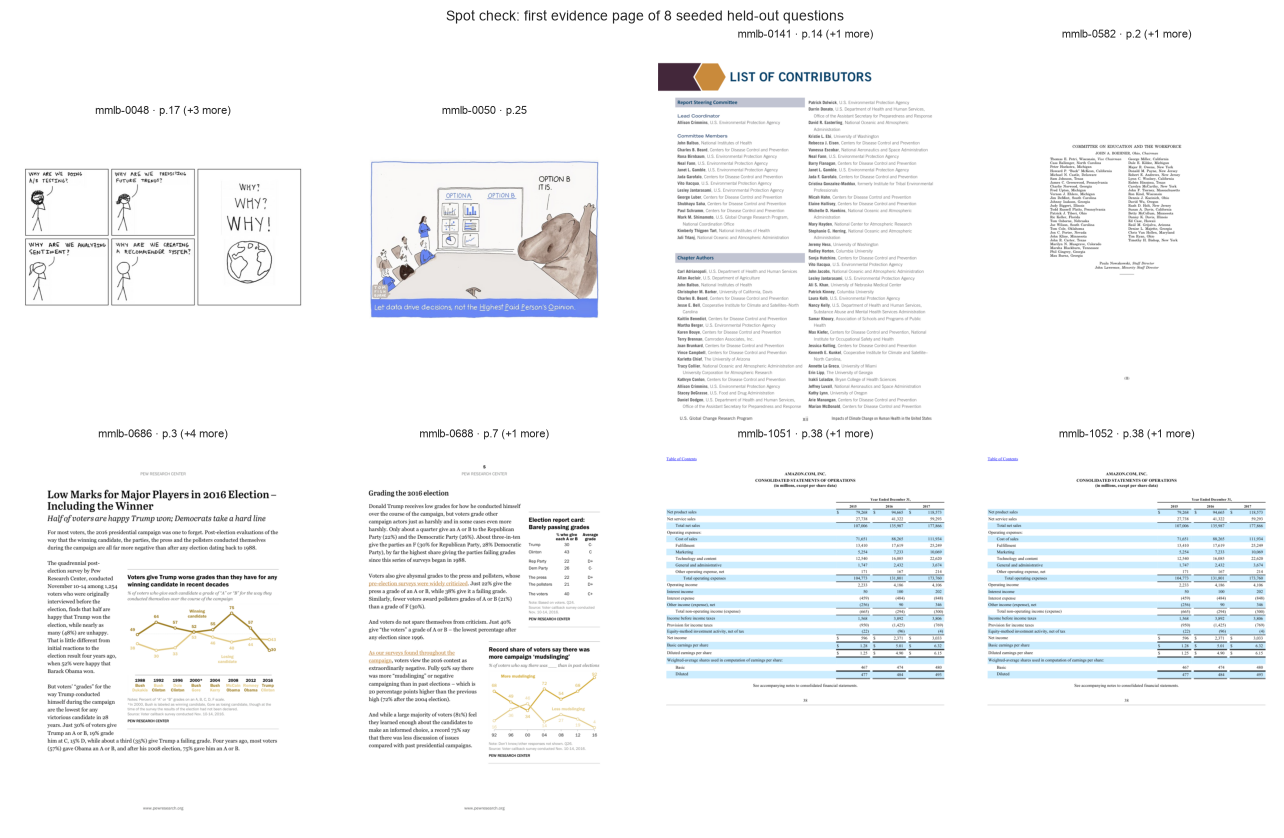

,doc,question,reference,evidence,sources,label,note
mmlb-0048,ddoseattle-150627210357-lv,How many hand drawn cartoons are included in the slides ...,4,"[17, 25, 40, 51]",[Figure],supported,"4 drawn cartoons on pp. 17, 25, 40, 51 (p. 40 is retro c..."
mmlb-0050,ddoseattle-150627210357-lv,"In the cartoon in page 25, what does the hippo represent?",highest paid person's opinion,[25],[Figure],supported,"p. 25: the hippo stands for the HiPPO, the highest paid ..."
mmlb-0141,efd88e41c5f2606c57929cac6c,How many chapter authors of this report come from Columb...,3,"[14, 15]",[Pure-text (Plain-text)],supported,"chapter authors from Columbia: Horton, Kinney (p. 14), P..."
mmlb-0582,e639029d16094ea71d964e2fb9,How many committee members from Texas are presented in t...,1,"[2, 5]","[Pure-text (Plain-text), Table]",supported,"p. 2 roster: 3 Texans on the committee; p. 5: of those, ..."
mmlb-0686,11-21-16-Updated-Post-Elec,How many line plots are there in the report?,8,"[3, 7, 33, 34, 35]",[Chart],supported,"line plots: p. 3 (1), 7 (1), 33 (2), 34 (2), 35 (2) = 8;..."
mmlb-0688,11-21-16-Updated-Post-Elec,How many charts are related to mudslinging?,3,"[7, 34]",[Chart],partly,"p. 7 has 1 mudslinging chart, p. 34 a 2-chart figure tit..."
mmlb-1051,AMAZON_2017_10K.pdf,What is Amazon's FY2017 days payable outstanding (DPO)?R...,97.75,"[38, 40]",[Table],partly,"inputs present (AP p. 40, cost of sales p. 38); 365 x av..."
mmlb-1052,AMAZON_2017_10K.pdf,what is Amazon's FY2017 Operating Profit Margin Before D...,0.073,"[38, 71]",[Table],supported,"(operating income 4,106 + depreciation 8,831, p. 71) / n..."


In [9]:
spot_rng = np.random.default_rng(SETTINGS["heldout_seed"])  # a fresh generator, as the spec states
spot_qids = sorted(spot_rng.choice(sorted(held_pop["qid"]), size=SETTINGS["spot_check_n"], replace=False).tolist())
spot = held_pop.set_index("qid").loc[spot_qids]

# Recorded by viewing each evidence page (the images below) against the reference answer, before any retrieval score.
SPOT_CHECK_LABELS = {  # qid -> (label, note); label in {"supported", "partly", "not supported"}. Recorded 2026-11-23 before any visual score.
    "mmlb-0048": ("supported", "4 drawn cartoons on pp. 17, 25, 40, 51 (p. 40 is retro clip art); completeness over the 63-slide deck not checked"),
    "mmlb-0050": ("supported", "p. 25: the hippo stands for the HiPPO, the highest paid person's opinion"),
    "mmlb-0141": ("supported", "chapter authors from Columbia: Horton, Kinney (p. 14), Perez Garcia-Pando (p. 15); printed xii-xiii = physical 14-15"),
    "mmlb-0582": ("supported", "p. 2 roster: 3 Texans on the committee; p. 5: of those, only Carter is listed as present"),
    "mmlb-0686": ("supported", "line plots: p. 3 (1), 7 (1), 33 (2), 34 (2), 35 (2) = 8; other pages not scanned"),
    "mmlb-0688": ("partly", "p. 7 has 1 mudslinging chart, p. 34 a 2-chart figure titled on mud-slinging and issues; 3 only if the issues chart counts"),
    "mmlb-1051": ("partly", "inputs present (AP p. 40, cost of sales p. 38); 365 x average AP / cost of sales = 97.70, reference 97.75"),
    "mmlb-1052": ("supported", "(operating income 4,106 + depreciation 8,831, p. 71) / net sales 177,866 = 0.073"),
}

fig, axes = plt.subplots(2, 4, figsize=(13, 8.5))
for ax, (qid, row) in zip(axes.flat, spot.iterrows()):
    page = row["evidence_pages"][0]
    ax.imshow(plt.imread(PROJECT_ROOT / all_pages.set_index(["doc_id", "page"]).loc[(row["doc_id"], page), "image_path"]))
    ax.set_title(f"{qid} · p.{page}" + (f" (+{len(row['evidence_pages']) - 1} more)" if len(row["evidence_pages"]) > 1 else ""), fontsize=8)
    ax.axis("off")
plt.suptitle("Spot check: first evidence page of 8 seeded held-out questions", fontsize=10)
plt.tight_layout()
plt.show()
pd.DataFrame({
    "doc": spot["doc_id"].str.slice(0, 26), "question": spot["question"].str.slice(0, 80), "reference": spot["answer"].astype(str).str.slice(0, 40),
    "evidence": spot["evidence_pages"], "sources": spot["evidence_sources"],
    "label": [SPOT_CHECK_LABELS.get(q, ("(not yet labelled)", ""))[0] for q in spot_qids],
    "note": [SPOT_CHECK_LABELS.get(q, ("", ""))[1] for q in spot_qids],
}, index=spot_qids)


**Spot check (8 seeded held-out questions, labelled before any visual-retrieval score existed): 6 supported, 2 partly, 0 not supported.**

- **Page alignment holds by eye.** Every annotated page is the physical page that holds the evidence, including documents whose printed page numbers differ from the physical ones: printed "xii" is physical 14 in `efd88e41`, and printed 5 is physical 7 in the Pew report. The offset test in section 3 repeats the check with the retriever.
- **The two partial cases are scoring issues, not alignment issues.**
  - `mmlb-0688`: the count depends on what counts as "a chart related to mudslinging".
  - `mmlb-1051`: the reference 97.75 is 0.05 off the standard DPO formula applied to the annotated pages.
- **Counting questions** (`0048`, `0686`) are supported by their pages, but their completeness over the whole document was not checked.

These labels describe annotation quality. They are not used to filter or weight any question.

## 3. BM25 baseline (arm A), reproduced

Notebook 01's BM25 is rebuilt here, with nothing changed:

- **Tokens:** lower-cased runs of `[a-z0-9]`.
- **Statistics:** computed per document, $k_1 = 1.5$, $b = 0.75$.
- **Ties:** broken by page number.

It must reproduce the frozen E0 run's **full** ranking for all 57 development questions, and notebook 01's Recall@5 0.689 and Hit@5 0.800.

**Retrieval input.** Both arms rank from one table with three columns: `qid`, `doc_id` and `question`. It carries no evidence pages, answers, formats or sources.


In [10]:
TOKEN_PATTERN = re.compile(r"[a-z0-9]+")


def tokenize(text):
    return TOKEN_PATTERN.findall(str(text).lower())


def build_bm25_index(page_texts):
    # page_texts: {page_number: text} for one PDF -> the statistics BM25 needs (notebook 01).
    tokens = {page: tokenize(text) for page, text in page_texts.items()}
    frequency = Counter(token for page_tokens in tokens.values() for token in set(page_tokens))
    n_pages = len(tokens)
    return {"term_counts": {page: Counter(t) for page, t in tokens.items()}, "lengths": {page: len(t) for page, t in tokens.items()},
            "avgdl": float(np.mean([len(t) for t in tokens.values()])),
            "idf": {token: log(1 + (n_pages - n_t + 0.5) / (n_t + 0.5)) for token, n_t in frequency.items()}}


def bm25_rank(index, query, k1=SETTINGS["bm25_k1"], b=SETTINGS["bm25_b"]):
    # [(page, score), ...] for every page, best first; ties broken by page number.
    terms = set(tokenize(query))
    scored = []
    for page, counts in index["term_counts"].items():
        length_factor = k1 * (1 - b + b * index["lengths"][page] / max(index["avgdl"], 1.0))
        scored.append((page, sum(index["idf"][t] * counts[t] * (k1 + 1) / (counts[t] + length_factor) for t in terms if counts[t])))
    return sorted(scored, key=lambda item: (-item[1], item[0]))


# The only input either retriever receives: question id, document and question string.
retrieval_questions = pd.concat([dev_q.assign(population="development"), held_q.assign(population="held-out")], ignore_index=True)[
    ["qid", "population", "doc_id", "question"]]
assert retrieval_questions["qid"].is_unique and len(retrieval_questions) == 57 + 118

started = time.perf_counter()
bm25_indexes = {doc_id: build_bm25_index(dict(zip(group["page"], group["text"]))) for doc_id, group in all_pages.groupby("doc_id")}
bm25_index_seconds = time.perf_counter() - started
started = time.perf_counter()
RANKINGS = {"A": {row.qid: bm25_rank(bm25_indexes[row.doc_id], row.question) for row in retrieval_questions.itertuples()}}
bm25_query_seconds = (time.perf_counter() - started) / len(retrieval_questions)

# Regression: full development rankings equal the frozen E0 text run (every page, every position); 01's numbers hold.
frozen_e0 = pd.read_csv(FROZEN_E0_TEXT_RUN / "scored_predictions.csv").set_index("qid")["ranking"].map(ast.literal_eval)
assert all([page for page, _ in RANKINGS["A"][qid]] == frozen_e0[qid] for qid in dev_q["qid"]) and len(frozen_e0) == 57
top5 = {qid: {page for page, _ in RANKINGS["A"][qid][:5]} for qid in dev_pop["qid"]}
dev_recall5 = np.mean([len(set(e) & top5[q]) / len(set(e)) for q, e in zip(dev_pop["qid"], dev_pop["evidence_pages"])])
dev_hit5 = np.mean([bool(set(e) & top5[q]) for q, e in zip(dev_pop["qid"], dev_pop["evidence_pages"])])
assert round(dev_recall5, 3) == 0.689 and round(dev_hit5, 3) == 0.800
print(f"BM25 reproduced: full rankings = frozen E0 on 57/57 development questions; Recall@5 {dev_recall5:.3f}, Hit@5 {dev_hit5:.3f} "
      f"(notebook 01: 0.689, 0.800). Index {bm25_index_seconds:.2f} s for {len(all_pages)} pages; {1e3 * bm25_query_seconds:.1f} ms per query.")


BM25 reproduced: full rankings = frozen E0 on 57/57 development questions; Recall@5 0.689, Hit@5 0.800 (notebook 01: 0.689, 0.800). Index 0.07 s for 842 pages; 0.1 ms per query.


### The context guard, rebuilt

The application keeps the **longest ranked prefix** of the top 5 whose prompt-token upper bound, plus 400 output tokens, fits GPT-4o-mini's 128,000-token context.

- **Text** is bounded by its UTF-8 byte count: byte-level BPE never needs more tokens than bytes.
- **Each page image** costs what the API bills for a high-detail image:
  1. fit the image inside 2048 × 2048;
  2. shrink its short side to 768 px if it is larger;
  3. count 512-px tiles $t$;
  4. the cost is $2{,}833 + 5{,}667\,t$ tokens.

A 768 × 994 page has 2 × 2 tiles and costs 25,501 tokens; a 1366 × 768 slide has 3 × 2 tiles and costs 36,835. Four letter pages fit and five do not, so the guard is not a choice of $k$: it depends on the **page shapes** of the ranked pages.

The rebuilt guard must give exactly the page lists that E4 sent to the model for the 57 development questions. It must also reproduce E4's evidence availability: 29 of 40 questions.


In [11]:
# The application's reader configuration (prompt mmlb-image-v1, verified by its frozen hash) and token rule.
IMAGE_PROMPT_VERSION = "mmlb-image-v1"
IMAGE_SYSTEM_PROMPT = """You answer questions about a single PDF document using only the page images provided.
Each page image is preceded by a tag [Page N], where N is the 1-based page number in the PDF.

Return a JSON object with exactly these keys:
  "answer": the shortest complete answer. Use a number (integer or decimal) when the answer is a number,
            and a JSON list when several items are asked for. If the page images do not contain the answer,
            use exactly the string "Not answerable".
  "cited_pages": a list of the page numbers N whose images support the answer ([] if "Not answerable").

Do not use knowledge outside the page images. Do not guess."""
assert hashlib.sha256((IMAGE_PROMPT_VERSION + IMAGE_SYSTEM_PROMPT).encode()).hexdigest()[:12] == "35ff2e8b91f9"
CONTEXT_TOKENS, OUTPUT_TOKENS, FRAMING_TOKENS = 128_000, 400, 100


def image_tokens(width, height):
    # GPT-4o-mini high detail: fit in 2048 x 2048, shrink the short side to 768 if larger, 2,833 + 5,667 per 512-px tile.
    scale = min(1.0, 2048 / max(width, height))
    width, height = width * scale, height * scale
    short_scale = 768 / min(width, height)
    if short_scale < 1:
        width, height = width * short_scale, height * short_scale
    return 2_833 + 5_667 * ceil(round(width, 6) / 512) * ceil(round(height, 6) / 512)


def guard(question, ranked_pages, doc_id, limit=CONTEXT_TOKENS - OUTPUT_TOKENS):
    # Longest ranked prefix whose prompt bound fits; returns (kept pages, dropped pages). Never reorders.
    total = FRAMING_TOKENS + len(IMAGE_SYSTEM_PROMPT.encode()) + len(f"Question: {question}\n\nPage images:".encode())
    kept = []
    for page in ranked_pages:
        cost = len(f"[Page {page}]".encode()) + image_tokens(*PAGE_SIZE[(doc_id, page)])
        if total + cost > limit:
            break
        kept.append(page)
        total += cost
    return kept, list(ranked_pages[len(kept):])


assert image_tokens(768, 994) == 25_501 and image_tokens(1366, 768) == 36_835 and image_tokens(1024, 768) == 25_501

# Regression against what E4 actually sent: the APP page lists and image sizes in the frozen execution log.
e4_app = {r["qid"]: r for r in map(json.loads, open(FROZEN_E4_RUN / "execution_log.jsonl")) if r["arm"] == "APP" and r["replicate_id"] == "main_r1"}
question_text = retrieval_questions.set_index("qid")["question"]
doc_of = retrieval_questions.set_index("qid")["doc_id"]
dev_supplied_A = {qid: guard(question_text[qid], [p for p, _ in RANKINGS["A"][qid][:5]], doc_of[qid])[0] for qid in dev_q["qid"]}
assert len(e4_app) == 57 and all(dev_supplied_A[qid] == e4_app[qid]["supplied_pages"] for qid in dev_q["qid"])
assert all([list(PAGE_SIZE[(doc_of[q], p)]) for p in r["supplied_pages"]] == r["image_dimensions"] for q, r in e4_app.items())
dev_hit_after_A = sum(bool(set(e) & set(dev_supplied_A[q])) for q, e in zip(dev_pop["qid"], dev_pop["evidence_pages"]))
assert dev_hit_after_A == 29
print(f"Guard reproduced: supplied pages = the frozen E4 APP requests on 57/57 questions (and their image sizes); "
      f"evidence supplied for {dev_hit_after_A}/40 answerable questions, as in E4.")


Guard reproduced: supplied pages = the frozen E4 APP requests on 57/57 questions (and their image sizes); evidence supplied for 29/40 answerable questions, as in E4.


In [12]:
# Held-out page convention, checked with the retriever (notebook 01's test): BM25 never sees the annotations, so if the
# benchmark's pages were shifted, its top-1 page would land next to the annotated page more often than on it.
offset_counts = pd.Series({
    label: int(sum(RANKINGS["A"][q][0][0] - offset in set(e) for q, e in zip(held_pop["qid"], held_pop["evidence_pages"])))
    for offset, label in {-1: "top-1 == p - 1", 0: "top-1 == p (1-based)", 1: "top-1 == p + 1 (0-based)"}.items()
}, name=f"held-out questions (of {len(held_pop)})")
assert offset_counts["top-1 == p (1-based)"] > max(offset_counts["top-1 == p - 1"], offset_counts["top-1 == p + 1 (0-based)"])
offset_counts.to_frame()


,held-out questions (of 101)
top-1 == p - 1,11
top-1 == p (1-based),42
top-1 == p + 1 (0-based),6


### Arm A is the application's retriever

On the development set, arm A equals the frozen runs above: the E0 rankings and the 57 page lists E4 sent.

The held-out documents are new, so the independent audit (`experiments/frozen/e5/AUDIT.json`) compares this notebook's construction with the application's own functions on every held-out page and question:

- `visualdoc.documents.extract_pages` gives the same text;
- `render_pages` gives the same image bytes;
- `BM25Index.rank` gives the same rankings;
- `select_pages_within_context`, run on the real PNG bytes, keeps the same pages.

The audit runs outside the notebooks, because AGENTS.md allows notebooks to import `src/visualdoc/` only in the sections that measure the application (02 §13, 03 §16–17).

## 4. Visual model (arm V): loading and page encoding

**Configuration.** Everything comes from the spec and from the checkpoint's own files:

- transformers' native `ColQwen2ForRetrieval` and `ColQwen2Processor`;
- bf16 on the M1 GPU (MPS), sdpa attention, batch size 1, under `torch.inference_mode()`;
- the preprocessing in the pinned `preprocessor_config.json`.

**What the processor does to a page.**

1. Qwen2-VL resizes the image so that both sides are multiples of 28 and the area lies between 3,136 and 602,112 pixels. A 768 × 994 page becomes 672 × 868.
2. It cuts the image into 14-px patches: here 48 × 62 = 2,976 patches.
3. The vision tower encodes the patches and merges each 2 × 2 block into one token: 744 visual tokens.
4. The language model reads them inside the prompt "Describe the image.", and every output token becomes a 128-d unit vector.

A query is `"Query: " + question` followed by 10 `<|endoftext|>` augmentation tokens.

**Two passes, identical arithmetic.** The library's forward computes `vlm.visual(pixel_values, grid_thw).pooler_output`, writes it into the token sequence and runs the language model. Here the forward is split in two:

- **Pass 1** loads the model, keeps only `vlm.visual` (1.3 GB) on the GPU, and stores each page's `pooler_output`.
- **Pass 2** loads the model again, replaces `vlm.visual` with a stub that returns the stored output, and calls the library's **unmodified** forward. The stub checks that the feature count matches the page's grid.

The last cell of this section re-encodes pages in a single pass and requires **bitwise** equality.

**Caching.**

- **Cache directory:** `data/cache/e5/colqwen2-v1.0-hf@ddc07d2317c8/<config hash>/`. The hash covers the model revision, weight hash, library versions, device, dtype, preprocessing, prompts and embedding rule, so a change in any of them starts a new cache.
- **Keys:** each page is keyed by the SHA-256 of its PNG, each query by the SHA-256 of its text.
- **Format:** bf16 safetensors with padding rows removed. Converting bf16 to float32 for scoring is exact.
- **Temporary files:** pass-1 features are deleted once pass 2 has used them.
- **Restarting:** an interrupted run resumes where it stopped.

In [13]:
from PIL import Image
from transformers import ColQwen2ForRetrieval, ColQwen2Processor

V_SPEC = SPEC["arms"]["V_colqwen2"]
DEVICE, DTYPE, ATTENTION = "mps", torch.bfloat16, "sdpa"
processor = ColQwen2Processor.from_pretrained(MODEL_DIR)
preprocessor_config = json.loads((MODEL_DIR / "preprocessor_config.json").read_text())
assert (preprocessor_config["min_pixels"], preprocessor_config["max_pixels"], preprocessor_config["patch_size"], preprocessor_config["merge_size"]) == (3136, 602112, 14, 2)
assert all(str(v) in V_SPEC["page_input"] for v in (3136, 602112))
assert processor.query_prefix == "Query: " and processor.query_augmentation_token == "<|endoftext|>"
assert processor.visual_prompt_prefix.replace("\n", "\\n") in V_SPEC["visual_prompt"]

ENCODER_CONFIG = {
    "repo": MODEL["repo"], "revision": MODEL["revision"], "weights_sha256": MODEL["weights_sha256"],
    "transformers": transformers.__version__, "torch": torch.__version__, "device": DEVICE, "dtype": "bfloat16",
    "attn_implementation": ATTENTION, "batch_size": 1, "page_image": "E1 profile: 768 x 1536 box, RGB PNG",
    "preprocessor_config_sha256": sha256_file(MODEL_DIR / "preprocessor_config.json"),
    "tokenizer_sha256": sha256_file(MODEL_DIR / "tokenizer.json"),
    "visual_prompt": processor.visual_prompt_prefix, "query_prefix": processor.query_prefix,
    "query_augmentation": f"10 x {processor.query_augmentation_token}",
    "embedding_rule": "model(**batch).embeddings; rows with attention_mask 0 removed; stored bf16",
}
CONFIG_HASH = hashlib.sha256(json.dumps(ENCODER_CONFIG, sort_keys=True).encode()).hexdigest()[:12]
CACHE_DIR = PROJECT_ROOT / "data" / "cache" / "e5" / MODEL_DIR.name / CONFIG_HASH
for sub in ("pages", "queries", "vision_features"):
    (CACHE_DIR / sub).mkdir(parents=True, exist_ok=True)
atomic_write_bytes(CACHE_DIR / "config.json", json.dumps(ENCODER_CONFIG, indent=1, sort_keys=True).encode())
# Resume after an interruption: drop half-written temporaries, and pass-1 features whose page embedding was already saved
# (pass 2 saves the embedding, then deletes the features; an interruption between the two leaves both).
stale_temporaries = sum(remove_stale_temporaries(CACHE_DIR / sub) for sub in ("pages", "queries", "vision_features")) + remove_stale_temporaries(E5_DIR)
orphaned_features = [f for f in (CACHE_DIR / "vision_features").glob("*.safetensors") if (CACHE_DIR / "pages" / f.name).is_file()]
for path in orphaned_features:
    path.unlink()
ENCODING_LOG = E5_DIR / "encoding_log.csv"


def page_cache_path(png_sha256):
    return CACHE_DIR / "pages" / f"{png_sha256}.safetensors"


def feature_path(png_sha256):
    return CACHE_DIR / "vision_features" / f"{png_sha256}.safetensors"


def query_key(question):
    return hashlib.sha256(question.encode()).hexdigest()


def query_cache_path(question):
    return CACHE_DIR / "queries" / f"{query_key(question)}.safetensors"


def load_page_image(relative_path):
    with Image.open(PROJECT_ROOT / relative_path) as image:
        return image.convert("RGB")


def append_log(rows):
    # Same bytes as appending to the CSV, but the whole file is replaced atomically: an interruption keeps the last complete log.
    existing = ENCODING_LOG.read_bytes() if ENCODING_LOG.is_file() else b""
    atomic_write_bytes(ENCODING_LOG, existing + pd.DataFrame(rows).to_csv(index=False, header=not existing).encode())


page_jobs = all_pages.drop_duplicates("sha256")[["population", "doc_id", "page", "sha256", "image_path"]].reset_index(drop=True)
pending_pages = page_jobs[~page_jobs["sha256"].map(lambda s: page_cache_path(s).is_file())]
pending_questions = sorted({q for q in retrieval_questions["question"] if not query_cache_path(q).is_file()})
SESSION = time.strftime("%Y%m%dT%H%M%SZ", time.gmtime())
print(f"Encoder configuration hash {CONFIG_HASH}; cache {CACHE_DIR.relative_to(PROJECT_ROOT)}; removed {stale_temporaries} stale "
      f"temporary files and {len(orphaned_features)} pass-1 feature files whose embedding was already saved.")
print(f"{len(page_jobs)} distinct page images ({len(all_pages)} pages); {len(pending_pages)} to encode; "
      f"{retrieval_questions['question'].nunique()} distinct questions, {len(pending_questions)} to encode.")

W1123 17:24:18.453000 13958 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


[transformers] Qwen2VLConfig got `key=rope_scaling` in kwargs but hasn't set it as attribute. For RoPE standardization you need to set `self.rope_parameters` in model's config. 


[transformers] Unrecognized keys in `rope_parameters` for 'rope_type'='default': {'mrope_section'}


Encoder configuration hash af02fac2cb9b; cache data/cache/e5/colqwen2-v1.0-hf@ddc07d2317c8/af02fac2cb9b; removed 0 stale temporary files and 0 pass-1 feature files whose embedding was already saved.
837 distinct page images (842 pages); 0 to encode; 175 distinct questions, 0 to encode.


In [14]:
# What the model receives: one page of each shape, and one query, through the processor (no model needed).
demo_rows = all_pages.assign(shape=all_pages["width_px"].astype(str) + "x" + all_pages["height_px"].astype(str)).drop_duplicates("shape").head(4)
image_pad_id = processor.tokenizer.convert_tokens_to_ids("<|image_pad|>")
demo = []
for row in demo_rows.itertuples():
    batch = processor(images=[load_page_image(row.image_path)], return_tensors="pt")
    t, h, w = batch["image_grid_thw"][0].tolist()
    demo.append({"page": f"{row.doc_id[:24]} p.{row.page}", "answering image (px)": row.shape, "model input (px)": f"{w * 14}x{h * 14}",
                 "pixels": w * h * 196, "14-px patches": t * h * w, "visual tokens (2x2 merged)": t * h * w // 4,
                 "sequence tokens": int(batch["input_ids"].shape[1]), "image tokens in sequence": int((batch["input_ids"] == image_pad_id).sum())})
demo = pd.DataFrame(demo)
assert (demo["visual tokens (2x2 merged)"] == demo["image tokens in sequence"]).all() and (demo["pixels"] <= 602_112).all()
display(demo)
example_question = question_text["mmlb-0033"]
tokens = processor.tokenizer.convert_ids_to_tokens(processor(text=[example_question], return_tensors="pt")["input_ids"][0])
print(f"Query for mmlb-0033 ({len(tokens)} tokens): {example_question!r}")
print(tokens)
assert tokens[-11:-1] == ["<|endoftext|>"] * 10

,page,answering image (px),model input (px),pixels,14-px patches,visual tokens (2x2 merged),sequence tokens,image tokens in sequence
0,2210.02442v1.pdf p.1,768x994,672x868,583296,2976,744,755,744
1,earlybird-110722143746-p p.1,1024x768,896x672,602112,3072,768,779,768
2,germanwingsdigitalcrisis p.1,1366x768,1008x560,564480,2880,720,731,720
3,watch_d.pdf p.1,768x1087,644x896,577024,2944,736,747,736


Query for mmlb-0033 (37 tokens): 'How many more millions of dollars was the median exit valuation in the USA compared to Europe at the time of the presentation?'
['Query', ':', 'ĠHow', 'Ġmany', 'Ġmore', 'Ġmillions', 'Ġof', 'Ġdollars', 'Ġwas', 'Ġthe', 'Ġmedian', 'Ġexit', 'Ġvaluation', 'Ġin', 'Ġthe', 'ĠUSA', 'Ġcompared', 'Ġto', 'ĠEurope', 'Ġat', 'Ġthe', 'Ġtime', 'Ġof', 'Ġthe', 'Ġpresentation', '?', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>', 'Ċ']


In [15]:
# Pass 1: the vision tower alone, on every page whose embedding is not cached yet.
def unpadded_pixel_values(batch):
    # The library's own unpadding (ColQwen2ForRetrieval.forward): keep each image's h * w patch rows.
    grid = batch["image_grid_thw"]
    offsets = grid[:, 1] * grid[:, 2]
    mask = torch.arange(batch["pixel_values"].shape[1]).unsqueeze(0) < offsets.unsqueeze(1)
    return batch["pixel_values"][mask]


process = psutil.Process()
PASS_PEAKS = {}
need_vision = pending_pages[~pending_pages["sha256"].map(lambda s: feature_path(s).is_file())]
if len(need_vision):
    started = time.perf_counter()
    model = ColQwen2ForRetrieval.from_pretrained(MODEL_DIR, dtype=DTYPE, attn_implementation=ATTENTION).eval()
    visual = model.vlm.visual
    model.vlm.visual = None
    del model
    gc.collect()
    visual.to(DEVICE)
    load_seconds = time.perf_counter() - started
    peak_rss, peak_mps, log_rows = process.memory_info().rss, torch.mps.driver_allocated_memory(), []
    with torch.inference_mode():
        for i, row in enumerate(need_vision.itertuples(), 1):
            t0 = time.perf_counter()
            batch = processor(images=[load_page_image(row.image_path)], return_tensors="pt")
            features = visual(unpadded_pixel_values(batch).to(DEVICE), grid_thw=batch["image_grid_thw"].to(DEVICE), return_dict=True).pooler_output
            torch.mps.synchronize()
            atomic_save_tensors({"features": features.cpu().contiguous()}, feature_path(row.sha256))
            peak_rss, peak_mps = max(peak_rss, process.memory_info().rss), max(peak_mps, torch.mps.driver_allocated_memory())
            log_rows.append({"session": SESSION, "pass": "vision", "key": row.sha256, "doc_id": row.doc_id, "page": row.page,
                             "seconds": time.perf_counter() - t0, "tokens": int(features.shape[0]), "load_seconds": load_seconds})
            if i % 50 == 0 or i == len(need_vision):
                append_log(log_rows)
                log_rows = []
                print(f"  pass 1: {i}/{len(need_vision)} pages, {time.perf_counter() - started:.0f} s", flush=True)
    PASS_PEAKS["vision"] = {"rss_gb": peak_rss / 1e9, "mps_driver_gb": peak_mps / 1e9, "load_seconds": load_seconds}
    del visual
    gc.collect()
    torch.mps.empty_cache()
    print(f"Pass 1 done: {len(need_vision)} pages in {time.perf_counter() - started:.0f} s; peak RSS {peak_rss / 1e9:.2f} GB, "
          f"peak MPS driver memory {peak_mps / 1e9:.2f} GB.")
else:
    print("Pass 1: nothing to do (every page has a cached embedding or cached vision features).")

Pass 1: nothing to do (every page has a cached embedding or cached vision features).


In [16]:
# Pass 2: the library's unmodified forward, with the vision tower replaced by the features of pass 1; then the queries.
class CachedVisionFeatures(torch.nn.Module):
    """Stands in for model.vlm.visual: returns the pass-1 output of the page being encoded."""

    def __init__(self):
        super().__init__()
        self.features = None

    def forward(self, pixel_values, grid_thw=None, return_dict=True, **kwargs):
        expected = int((grid_thw.prod(-1) // 4).sum())  # one feature per 2 x 2 block of patches
        assert self.features is not None and self.features.shape[0] == expected, "cached features do not match this page"
        return SimpleNamespace(pooler_output=self.features)


def encode_with(model, batch):
    embeddings = model(**batch).embeddings
    torch.mps.synchronize()
    keep = batch["attention_mask"][0].bool()
    return embeddings[0][keep].cpu().contiguous()  # bf16, padding rows removed


if len(pending_pages) or pending_questions:
    started = time.perf_counter()
    model = ColQwen2ForRetrieval.from_pretrained(MODEL_DIR, dtype=DTYPE, attn_implementation=ATTENTION).eval()
    stub = CachedVisionFeatures()
    model.vlm.visual = stub  # the real vision weights are released before the move to the GPU
    gc.collect()
    model.to(DEVICE)
    load_seconds = time.perf_counter() - started
    peak_rss, peak_mps, log_rows = process.memory_info().rss, torch.mps.driver_allocated_memory(), []
    with torch.inference_mode():
        for i, row in enumerate(pending_pages.itertuples(), 1):
            t0 = time.perf_counter()
            batch = processor(images=[load_page_image(row.image_path)], return_tensors="pt").to(DEVICE)
            stub.features = load_file(feature_path(row.sha256))["features"].to(DEVICE)
            embedding = encode_with(model, batch)
            atomic_save_tensors({"embedding": embedding}, page_cache_path(row.sha256))  # embedding first, then drop its features
            feature_path(row.sha256).unlink()
            peak_rss, peak_mps = max(peak_rss, process.memory_info().rss), max(peak_mps, torch.mps.driver_allocated_memory())
            log_rows.append({"session": SESSION, "pass": "language", "key": row.sha256, "doc_id": row.doc_id, "page": row.page,
                             "seconds": time.perf_counter() - t0, "tokens": int(embedding.shape[0]), "load_seconds": load_seconds})
            if i % 50 == 0 or i == len(pending_pages):
                append_log(log_rows)
                log_rows = []
                print(f"  pass 2: {i}/{len(pending_pages)} pages, {time.perf_counter() - started:.0f} s", flush=True)
        stub.features = None
        for question in pending_questions:
            t0 = time.perf_counter()
            embedding = encode_with(model, processor(text=[question], return_tensors="pt").to(DEVICE))
            atomic_save_tensors({"embedding": embedding}, query_cache_path(question))
            log_rows.append({"session": SESSION, "pass": "query", "key": query_key(question), "doc_id": "", "page": 0,
                             "seconds": time.perf_counter() - t0, "tokens": int(embedding.shape[0]), "load_seconds": load_seconds})
        if log_rows:
            append_log(log_rows)
    PASS_PEAKS["language"] = {"rss_gb": peak_rss / 1e9, "mps_driver_gb": peak_mps / 1e9, "load_seconds": load_seconds}
    del model, stub
    gc.collect()
    torch.mps.empty_cache()
    print(f"Pass 2 done: {len(pending_pages)} pages and {len(pending_questions)} queries in {time.perf_counter() - started:.0f} s; "
          f"peak RSS {peak_rss / 1e9:.2f} GB, peak MPS driver memory {peak_mps / 1e9:.2f} GB.")
else:
    print("Pass 2: nothing to do (every page and question has a cached embedding).")
assert all(page_cache_path(s).is_file() for s in page_jobs["sha256"]) and all(query_cache_path(q).is_file() for q in retrieval_questions["question"])
assert not any((CACHE_DIR / "vision_features").iterdir()), "unconsumed pass-1 features remain"

Pass 2: nothing to do (every page and question has a cached embedding).


In [17]:
# Equivalence and determinism: re-encode one page per population and two queries with the ordinary single-pass forward
# (the whole model on the GPU, a few minutes on this machine) and require bitwise equality with the two-pass cache.
# Set E5_SKIP_MODEL_CHECKS=1 to skip on a machine without the checkpoint; the result is then marked as not re-verified.
SINGLE_PASS_CHECK = {"run": os.environ.get("E5_SKIP_MODEL_CHECKS") != "1"}
if SINGLE_PASS_CHECK["run"]:
    check_pages = page_jobs.groupby("population").head(1)
    check_questions = retrieval_questions.groupby("population").head(1)  # labelled by id: no question text in saved outputs
    model = ColQwen2ForRetrieval.from_pretrained(MODEL_DIR, dtype=DTYPE, attn_implementation=ATTENTION).eval().to(DEVICE)
    results = []
    with torch.inference_mode():
        for row in check_pages.itertuples():
            t0 = time.perf_counter()
            fresh = encode_with(model, processor(images=[load_page_image(row.image_path)], return_tensors="pt").to(DEVICE))
            results.append({"item": f"page {row.doc_id[:24]} p.{row.page}", "seconds (single pass)": round(time.perf_counter() - t0, 1),
                            "bitwise equal to cache": torch.equal(fresh, load_file(page_cache_path(row.sha256))["embedding"])})
        for row in check_questions.itertuples():
            fresh = encode_with(model, processor(text=[row.question], return_tensors="pt").to(DEVICE))
            results.append({"item": f"query {row.qid}", "seconds (single pass)": None,
                            "bitwise equal to cache": torch.equal(fresh, load_file(query_cache_path(row.question))["embedding"])})
    del model
    gc.collect()
    torch.mps.empty_cache()
    SINGLE_PASS_CHECK["results"] = results
    display(pd.DataFrame(results))
    assert all(r["bitwise equal to cache"] for r in results), "two-pass and single-pass embeddings differ"
    print("Single-pass forward reproduces the cached two-pass embeddings bit for bit.")
else:
    print("Skipped (E5_SKIP_MODEL_CHECKS=1): equivalence not re-verified in this execution.")

[transformers] Qwen2VLConfig got `key=rope_scaling` in kwargs but hasn't set it as attribute. For RoPE standardization you need to set `self.rope_parameters` in model's config. 


[transformers] Unrecognized keys in `rope_parameters` for 'rope_type'='default': {'mrope_section'}


Loading weights:   0%|          | 0/731 [00:00<?, ?it/s]

,item,seconds (single pass),bitwise equal to cache
0,page 2210.02442v1.pdf p.1,34.7,True
1,page 2312.10997v5.pdf p.1,31.3,True
2,query mmlb-0033,NaN,True
3,query mmlb-0042,NaN,True


Single-pass forward reproduces the cached two-pass embeddings bit for bit.


## 5. Query encoding and retrieval scoring

A query is $N_q \approx 20$–$40$ vectors $q_i$ and a page is $N_d \approx 700$–$780$ vectors $d_j$, all of unit length. MaxSim takes the similarity matrix $Q D^\top \in \mathbb R^{N_q \times N_d}$, keeps the maximum of each row (each query token's best page token) and sums:

$$s(q, d) = \sum_i \max_j \langle q_i, d_j \rangle = \texttt{(Q @ D.T).max(dim=1).sum()} .$$

The cell below does this by hand on one question. It shows which query tokens contribute most, and where on the best page their best matches lie, then checks the result against the library's `score_retrieval`.

Every page of the PDF is scored in float32. Ties are broken by page number, as in BM25. The full ranking is computed twice and must be identical, which shows the scoring is deterministic.

Arm H fuses the two full rankings, $1/(60 + r_A) + 1/(60 + r_V)$ (exploratory).

mmlb-0033: Q (37, 128), best page p.6 D (779, 128), similarity matrix (37, 779); s(q, d) = 23.716


,1,0,13,18,14,31,30,29
query token,:,Query,Ġin,ĠEurope,Ġthe,<|endoftext|>,<|endoftext|>,<|endoftext|>
max similarity,0.994,0.989,0.849,0.849,0.846,0.833,0.832,0.829
best page token,2,0,655,561,655,656,655,655


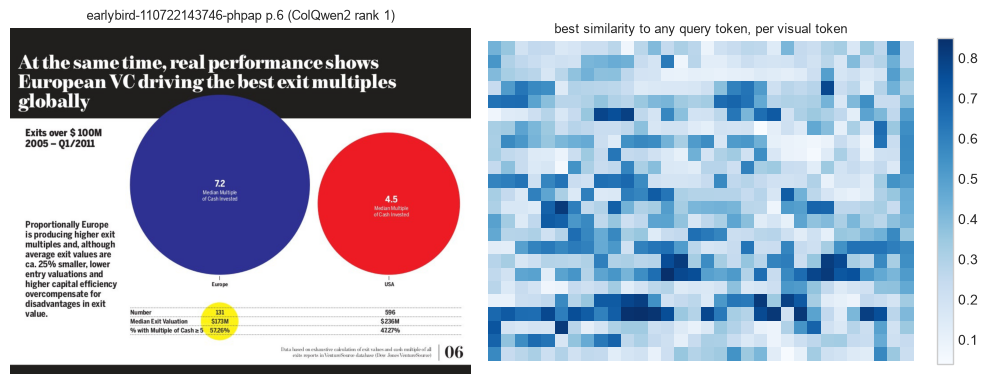

processor.score_retrieval agrees with the hand-written MaxSim on all 41 pages (max |difference| 0.0e+00).


In [18]:
PAGE_EMB = {sha: load_file(page_cache_path(sha))["embedding"].float() for sha in page_jobs["sha256"]}  # bf16 -> float32 is exact
QUERY_EMB = {q: load_file(query_cache_path(q))["embedding"].float() for q in retrieval_questions["question"].unique()}
page_sha = all_pages.set_index(["doc_id", "page"])["sha256"]
DOC_PAGES = {doc_id: sorted(group["page"]) for doc_id, group in all_pages.groupby("doc_id")}


def maxsim(query, page):
    # Late interaction: each query vector's best page vector, summed.
    return float((query @ page.T).max(dim=1).values.sum())


# By hand on one question (01's example): its best page under ColQwen2, token by token.
demo_qid = "mmlb-0033"
demo_doc, demo_question = doc_of[demo_qid], question_text[demo_qid]
Q = QUERY_EMB[demo_question]
demo_scores = {page: maxsim(Q, PAGE_EMB[page_sha[(demo_doc, page)]]) for page in DOC_PAGES[demo_doc]}
best_page = min(demo_scores, key=lambda p: (-demo_scores[p], p))
D = PAGE_EMB[page_sha[(demo_doc, best_page)]]
similarity = Q @ D.T
best_sim, best_j = similarity.max(dim=1)
query_tokens = processor.tokenizer.convert_ids_to_tokens(processor(text=[demo_question], return_tensors="pt")["input_ids"][0])
assert len(query_tokens) == Q.shape[0]
print(f"{demo_qid}: Q {tuple(Q.shape)}, best page p.{best_page} D {tuple(D.shape)}, similarity matrix {tuple(similarity.shape)}; "
      f"s(q, d) = {best_sim.sum():.3f}")
display(pd.DataFrame({"query token": query_tokens, "max similarity": best_sim.numpy().round(3), "best page token": best_j.numpy()})
        .sort_values("max similarity", ascending=False).head(8).T)

# Where the matches fall: for each image token of the page, its best similarity to any query token, on the 2x2-merged grid.
demo_batch = processor(images=[load_page_image(all_pages.set_index(["doc_id", "page"]).loc[(demo_doc, best_page), "image_path"])], return_tensors="pt")
_, grid_h, grid_w = demo_batch["image_grid_thw"][0].tolist()
image_positions = (demo_batch["input_ids"][0] == image_pad_id).nonzero().squeeze(1)
assert demo_batch["input_ids"].shape[1] == D.shape[0] and len(image_positions) == grid_h * grid_w // 4
heat = similarity[:, image_positions].max(dim=0).values.reshape(grid_h // 2, grid_w // 2).numpy()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
page_image = load_page_image(all_pages.set_index(["doc_id", "page"]).loc[(demo_doc, best_page), "image_path"])
axes[0].imshow(page_image)
axes[0].set_title(f"{demo_doc[:28]} p.{best_page} (ColQwen2 rank 1)", fontsize=9)
shown = axes[1].imshow(heat, cmap="Blues")
axes[1].set_title("best similarity to any query token, per visual token", fontsize=9)
fig.colorbar(shown, ax=axes[1], fraction=0.035)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

# The library's scorer gives the same scores (it pads pages to equal length with zero vectors).
doc_embeddings = [PAGE_EMB[page_sha[(demo_doc, p)]] for p in DOC_PAGES[demo_doc]]
library = processor.score_retrieval([Q], doc_embeddings, output_dtype=torch.float32)[0].numpy()
gap = np.abs(library - np.array([demo_scores[p] for p in DOC_PAGES[demo_doc]])).max()
assert gap < 1e-3, gap
print(f"processor.score_retrieval agrees with the hand-written MaxSim on all {len(doc_embeddings)} pages (max |difference| {gap:.1e}).")

In [19]:
def visual_rank(doc_id, question):
    # [(page, MaxSim score), ...] for every page of the PDF, best first; ties broken by page number.
    query = QUERY_EMB[question]
    scored = [(page, maxsim(query, PAGE_EMB[page_sha[(doc_id, page)]])) for page in DOC_PAGES[doc_id]]
    return sorted(scored, key=lambda item: (-item[1], item[0]))


def rrf_rank(ranking_a, ranking_b, k=SETTINGS["rrf_k"]):
    # Reciprocal rank fusion of two full rankings (1-based ranks); ties broken by page number.
    rank_a = {page: i + 1 for i, (page, _) in enumerate(ranking_a)}
    rank_b = {page: i + 1 for i, (page, _) in enumerate(ranking_b)}
    scored = [(page, 1 / (k + rank_a[page]) + 1 / (k + rank_b[page])) for page in rank_a]
    return sorted(scored, key=lambda item: (-item[1], item[0]))


started = time.perf_counter()
RANKINGS["V"] = {row.qid: visual_rank(row.doc_id, row.question) for row in retrieval_questions.itertuples()}
visual_score_seconds = (time.perf_counter() - started) / len(retrieval_questions)
assert {row.qid: visual_rank(row.doc_id, row.question) for row in retrieval_questions.itertuples()} == RANKINGS["V"]  # deterministic
RANKINGS["H"] = {qid: rrf_rank(RANKINGS["A"][qid], RANKINGS["V"][qid]) for qid in retrieval_questions["qid"]}
ARMS = ["A", "V", "H"]
ARM_LABEL = {"A": "A: OCR + BM25", "V": "V: ColQwen2", "H": "H: fusion (exploratory)"}

for arm in ARMS:  # every ranking is a permutation of its PDF's 1-based pages
    assert all(sorted(p for p, _ in RANKINGS[arm][row.qid]) == DOC_PAGES[row.doc_id] for row in retrieval_questions.itertuples())
top5_ties = sum(len({round(s, 6) for _, s in RANKINGS["V"][q][:6]}) < 6 for q in retrieval_questions["qid"])
bm25_zero = sum(RANKINGS["A"][q][0][1] == 0 for q in retrieval_questions["qid"])
print(f"Ranked {len(retrieval_questions)} questions x every page with ColQwen2 ({1e3 * visual_score_seconds:.1f} ms per question, "
      f"from cached embeddings); rankings identical on recomputation.")
print(f"Score ties among the top 6: ColQwen2 {top5_ties} questions. BM25 questions where every page scores 0 (order = page order): {bm25_zero}.")

Ranked 175 questions x every page with ColQwen2 (3.6 ms per question, from cached embeddings); rankings identical on recomputation.
Score ties among the top 6: ColQwen2 0 questions. BM25 questions where every page scores 0 (order = page order): 0.


In [20]:
# Annotations never enter retrieval. (1) The ranking functions take only a document and a question string, and the table
# they read has no annotation column. (2) Scrambling every annotation column of the benchmark leaves all rankings unchanged.
import inspect

assert list(inspect.signature(visual_rank).parameters) == ["doc_id", "question"]
assert list(inspect.signature(bm25_rank).parameters) == ["index", "query", "k1", "b"]
assert set(retrieval_questions.columns) == {"qid", "population", "doc_id", "question"}
annotation_columns = ["answer", "answer_format", "evidence_pages", "evidence_sources", "answerable", "n_evidence_pages"]
scrambled = bench.copy()
scrambled[annotation_columns] = scrambled[annotation_columns].sample(frac=1, random_state=0).to_numpy()
scrambled_input = scrambled[scrambled["qid"].isin(retrieval_questions["qid"])][["qid", "doc_id", "question"]]
assert all(bm25_rank(bm25_indexes[r.doc_id], r.question) == RANKINGS["A"][r.qid] and visual_rank(r.doc_id, r.question) == RANKINGS["V"][r.qid]
           for r in scrambled_input.itertuples())
print(f"Leakage check: rankings of all {len(scrambled_input)} questions are unchanged after scrambling {len(annotation_columns)} annotation columns.")

Leakage check: rankings of all 175 questions are unchanged after scrambling 6 annotation columns.


## 6. What reaches the model: the same context guard for every arm

Each ranking's top 5 goes through the guard of section 3. Because the guard depends on page shapes, the number of pages kept depends on the document:

- 4 for US-letter, A4 and 4:3 pages;
- 3 for 16:9 slides;
- possibly a different number per question in documents with mixed page sizes.

Within one document, both arms therefore get the same page budget.

In [21]:
SUPPLIED, DROPPED = {arm: {} for arm in ARMS}, {arm: {} for arm in ARMS}
for arm in ARMS:
    for row in retrieval_questions.itertuples():
        top = [page for page, _ in RANKINGS[arm][row.qid][:SETTINGS["top_k"]]]
        SUPPLIED[arm][row.qid], DROPPED[arm][row.qid] = guard(row.question, top, row.doc_id)
assert all(SUPPLIED["A"][q] == dev_supplied_A[q] == e4_app[q]["supplied_pages"] for q in dev_q["qid"])  # arm A = what E4 sent

pages_kept = pd.DataFrame([{"population": row.population, "arm": arm, "pages supplied": len(SUPPLIED[arm][row.qid])}
                           for arm in ARMS for row in retrieval_questions.itertuples()])
display(pages_kept.groupby(["population", "arm"])["pages supplied"].value_counts().unstack(fill_value=0)
        .assign(mean=pages_kept.groupby(["population", "arm"])["pages supplied"].mean().round(2)))
mixed = all_pages.assign(tokens=[image_tokens(w, h) for w, h in zip(all_pages["width_px"], all_pages["height_px"])]).groupby("doc_id")["tokens"].nunique()
print("Documents whose pages have more than one image-token cost:", {d[:40]: int(n) for d, n in mixed[mixed > 1].items()} or "none")

pages supplied    3    4  mean
population  arm               
development A    21   36  3.63
            H    21   36  3.63
            V    21   36  3.63
held-out    A    13  105  3.89
            H    13  105  3.89
            V    13  105  3.89

Documents whose pages have more than one image-token cost: none


## 7. Metrics and paired analysis

One row per question of the two evidence populations (40 development, held-out as counted in section 2), with every metric for every arm. The definitions are those of the Method section, and all are computed per question and then averaged.

**Before the guard** (from the full ranking):

- Recall@$k$ and Hit@$k$;
- the rank of the best evidence page, and MRR;
- nDCG@5.

**After the guard** (on the supplied pages):

- evidence pages supplied, and Recall, Hit and Complete;
- evidence pages lost to the guard.

In [22]:
def question_metrics(evidence, ranking, supplied, dropped):
    E = set(evidence)
    pages = [page for page, _ in ranking]
    first_rank = min(pages.index(p) + 1 for p in E)
    metrics = {"first_rank": first_rank, "mrr": 1 / first_rank}
    for k in SETTINGS["k_values"]:
        metrics[f"recall@{k}"] = len(E & set(pages[:k])) / len(E)
        metrics[f"hit@{k}"] = float(bool(E & set(pages[:k])))
    dcg = sum(1 / log2(i + 2) for i, p in enumerate(pages[:5]) if p in E)
    metrics["ndcg@5"] = dcg / sum(1 / log2(i + 2) for i in range(min(len(E), 5)))
    found = E & set(supplied)
    metrics.update(evidence_supplied=len(found), recall_after=len(found) / len(E), hit_after=float(bool(found)),
                   complete_after=float(found == E), n_supplied=len(supplied), evidence_lost_to_guard=len(E & set(dropped)))
    return metrics


evidence_questions = pd.concat([dev_pop.assign(population="development"), held_pop.assign(population="held-out")], ignore_index=True)
ocr_page = all_pages.set_index(["doc_id", "page"])["ocr_used"]
rows = []
for q in evidence_questions.itertuples():
    row = {"qid": q.qid, "population": q.population, "doc_id": q.doc_id, "doc_type": q.doc_type, "answer_format": q.answer_format,
           "evidence_pages": sorted(set(q.evidence_pages)), "evidence_sources": list(q.evidence_sources), "n_evidence": len(set(q.evidence_pages)),
           "page_count": len(DOC_PAGES[q.doc_id]), "evidence_on_ocr_page": any(ocr_page[(q.doc_id, p)] for p in q.evidence_pages)}
    for arm in ARMS:
        row.update({f"{name}_{arm}": value for name, value in
                    question_metrics(q.evidence_pages, RANKINGS[arm][q.qid], SUPPLIED[arm][q.qid], DROPPED[arm][q.qid]).items()})
        row[f"top5_{arm}"] = [page for page, _ in RANKINGS[arm][q.qid][:5]]
        row[f"supplied_{arm}"] = SUPPLIED[arm][q.qid]
    rows.append(row)
per_question = pd.DataFrame(rows)
assert len(per_question) == len(dev_pop) + len(held_pop)
METRICS = ["recall_after", "hit_after", "complete_after", "recall@1", "recall@3", "recall@4", "recall@5",
           "hit@1", "hit@3", "hit@4", "hit@5", "mrr", "ndcg@5", "n_supplied", "evidence_lost_to_guard"]


def summary_table(population):
    frame = per_question[per_question["population"] == population]
    table = pd.DataFrame({ARM_LABEL[arm]: {m: frame[f"{m}_{arm}"].mean() for m in METRICS} for arm in ARMS})
    counts = pd.DataFrame({ARM_LABEL[arm]: {f"questions with evidence supplied (of {len(frame)})": int(frame[f"hit_after_{arm}"].sum()),
                                            f"questions with all evidence supplied (of {len(frame)})": int(frame[f"complete_after_{arm}"].sum())}
                           for arm in ARMS})
    return pd.concat([table.round(3), counts])

In [23]:
# Development set (6 documents, 40 questions): regression and diagnostics only. Earlier experiments tuned the
# application on these questions, and the spec makes no decision here.
dev_summary = summary_table("development")
dev_frame = per_question[per_question["population"] == "development"]
assert round(dev_frame["recall@5_A"].mean(), 3) == 0.689 and round(dev_frame["hit@5_A"].mean(), 3) == 0.800
assert int(dev_frame["hit_after_A"].sum()) == 29 and int(dev_frame["hit@5_A"].sum()) == 32  # E4: 32/40 retrieved, 29/40 supplied
print("Development (exploratory). Arm A reproduces notebook 01 (Recall@5 0.689, Hit@5 0.800) and E4 (32/40 -> 29/40).")
dev_summary

Development (exploratory). Arm A reproduces notebook 01 (Recall@5 0.689, Hit@5 0.800) and E4 (32/40 -> 29/40).


,A: OCR + BM25,V: ColQwen2,H: fusion (exploratory)
recall_after,0.608,0.826,0.702
hit_after,0.725,0.950,0.825
complete_after,0.500,0.700,0.600
recall@1,0.346,0.536,0.517
recall@3,0.608,0.784,0.698
recall@4,0.629,0.843,0.711
recall@5,0.689,0.861,0.798
hit@1,0.400,0.675,0.625
hit@3,0.725,0.925,0.800
hit@4,0.725,0.950,0.825


In [24]:
# Held-out set: the primary evaluation.
held_summary = summary_table("held-out")
held_frame = per_question[per_question["population"] == "held-out"]
print(f"Held-out: {len(held_frame)} questions in {held_frame['doc_id'].nunique()} documents.")
held_summary

Held-out: 101 questions in 14 documents.


,A: OCR + BM25,V: ColQwen2,H: fusion (exploratory)
recall_after,0.526,0.721,0.631
hit_after,0.653,0.851,0.772
complete_after,0.416,0.604,0.505
recall@1,0.321,0.520,0.392
recall@3,0.475,0.698,0.613
recall@4,0.541,0.726,0.646
recall@5,0.556,0.762,0.687
hit@1,0.416,0.683,0.535
hit@3,0.584,0.842,0.752
hit@4,0.673,0.851,0.772


In [25]:
def cluster_bootstrap(frame, column):
    # 95 % percentile interval of the question-weighted mean of `column`, resampling documents with replacement.
    docs = sorted(frame["doc_id"].unique())
    sums = frame.groupby("doc_id")[column].sum()[docs].to_numpy()
    counts = frame.groupby("doc_id").size()[docs].to_numpy()
    draws = np.random.default_rng(SETTINGS["stat_seed"]).integers(0, len(docs), size=(SETTINGS["bootstrap_resamples"], len(docs)))
    return np.percentile(sums[draws].sum(axis=1) / counts[draws].sum(axis=1), [2.5, 97.5])


def sign_flip_p(frame, column):
    # Exact two-sided document-level test: under H0 each document's mean difference is symmetric around 0.
    means = frame.groupby("doc_id")[column].mean().to_numpy()
    flips = np.array(list(product([1, -1], repeat=len(means))))
    return float(np.mean(np.abs((flips * means).mean(axis=1)) >= abs(means.mean()) - 1e-12))


def mcnemar_exact_p(better, worse):
    n = better + worse
    return 1.0 if n == 0 else min(1.0, 2 * sum(comb(n, i) for i in range(min(better, worse) + 1)) / 2 ** n)


def paired(population, metric, treatment="V", control="A"):
    frame = per_question[per_question["population"] == population].copy()
    frame["diff"] = frame[f"{metric}_{treatment}"] - frame[f"{metric}_{control}"]
    low, high = cluster_bootstrap(frame, "diff")
    lodo = [frame.loc[frame["doc_id"] != d, "diff"].mean() for d in sorted(frame["doc_id"].unique())]
    result = {"population": population, "metric": metric, "comparison": f"{treatment} - {control}",
              control: frame[f"{metric}_{control}"].mean(), treatment: frame[f"{metric}_{treatment}"].mean(),
              "delta": frame["diff"].mean(), "ci_low": low, "ci_high": high, "sign_flip_p": sign_flip_p(frame, "diff"),
              "better": int((frame["diff"] > 1e-12).sum()), "worse": int((frame["diff"] < -1e-12).sum()),
              "same": int((frame["diff"].abs() <= 1e-12).sum()), "lodo_min": min(lodo), "lodo_max": max(lodo),
              "questions": len(frame), "documents": frame["doc_id"].nunique()}
    if metric.startswith("hit"):
        result["mcnemar_p"] = mcnemar_exact_p(result["better"], result["worse"])
    return result


PAIRED_METRICS = ["recall_after", "hit_after", "complete_after", "recall@5", "mrr", "ndcg@5"]
paired_results = pd.DataFrame([paired(pop, m, t, c) for pop in ("held-out", "development") for (t, c) in (("V", "A"), ("H", "A"), ("H", "V"))
                               for m in PAIRED_METRICS])
paired_results["role"] = np.where((paired_results["population"] == "held-out") & (paired_results["comparison"] == "V - A"),
                                  np.where(paired_results["metric"] == "recall_after", "PRIMARY",
                                           np.where(paired_results["metric"].isin(["hit_after", "complete_after"]), "key secondary", "secondary")),
                                  "exploratory")
columns = ["role", "population", "comparison", "metric", "A", "V", "H", "delta", "ci_low", "ci_high", "sign_flip_p", "mcnemar_p",
           "better", "worse", "same", "lodo_min", "lodo_max", "questions", "documents"]
display(paired_results[columns].round(3).fillna(""))

/var/folders/5g/qf_vww7d3vl8k5x593qbwpzw0000gn/T/ipykernel_13958/2064559931.py:47: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(paired_results[columns].round(3).fillna(""))


,role,population,comparison,metric,A,V,H,delta,ci_low,ci_high,sign_flip_p,mcnemar_p,better,worse,same,lodo_min,lodo_max,questions,documents
0,PRIMARY,held-out,V - A,recall_after,0.526,0.721,,0.195,0.110,0.309,0.000,,31,6,64,0.172,0.229,101,14
1,key secondary,held-out,V - A,hit_after,0.653,0.851,,0.198,0.102,0.325,0.002,0.0,23,3,75,0.170,0.235,101,14
2,key secondary,held-out,V - A,complete_after,0.416,0.604,,0.188,0.099,0.308,0.002,,23,4,74,0.168,0.224,101,14
3,secondary,held-out,V - A,recall@5,0.556,0.762,,0.207,0.115,0.326,0.000,,33,5,63,0.185,0.248,101,14
4,secondary,held-out,V - A,mrr,0.539,0.77,,0.231,0.152,0.336,0.000,,45,13,43,0.209,0.256,101,14
5,secondary,held-out,V - A,ndcg@5,0.482,0.709,,0.227,0.147,0.332,0.000,,45,10,46,0.206,0.260,101,14
6,exploratory,held-out,H - A,recall_after,0.526,,0.631,0.106,0.061,0.159,0.002,,19,3,79,0.095,0.120,101,14
7,exploratory,held-out,H - A,hit_after,0.653,,0.772,0.119,0.058,0.194,0.008,0.0,12,0,89,0.096,0.141,101,14
8,exploratory,held-out,H - A,complete_after,0.416,,0.505,0.089,0.035,0.157,0.031,,11,2,88,0.074,0.096,101,14
9,exploratory,held-out,H - A,recall@5,0.556,,0.687,0.132,0.071,0.210,0.001,,20,0,81,0.114,0.157,101,14


In [26]:
# The pre-registered decision rule, applied to the held-out primary endpoint only.
lookup = paired_results.set_index(["population", "comparison", "metric"])
primary = lookup.loc[("held-out", "V - A", "recall_after")]
hit_delta = lookup.loc[("held-out", "V - A", "hit_after"), "delta"]
more_evidence = int((held_frame["evidence_supplied_V"] > held_frame["evidence_supplied_A"]).sum())
less_evidence = int((held_frame["evidence_supplied_V"] < held_frame["evidence_supplied_A"]).sum())
delta_min = SETTINGS["min_meaningful_difference"]
conditions = {
    f"delta >= {delta_min}": primary["delta"] >= delta_min,
    "bootstrap lower bound > 0": primary["ci_low"] > 0,
    "delta Hit_after >= 0": hit_delta >= 0,
    f"questions with less evidence under V ({less_evidence}) <= half of those with more ({more_evidence})": less_evidence <= more_evidence / 2,
}
if all(conditions.values()):
    VERDICT = "visual_improves_evidence"
elif primary["delta"] <= -delta_min and primary["ci_high"] < 0:
    VERDICT = "visual_worse"
elif -delta_min < primary["ci_low"] and primary["ci_high"] < delta_min:
    VERDICT = "no_meaningful_difference"
else:
    VERDICT = "inconclusive"
RECOMMENDATION = SPEC["decision_rule"]["recommendation_map"][VERDICT]
display(pd.Series(conditions, name="holds").to_frame())
print(f"Primary (held-out Recall_after, V - A): {primary['A']:.3f} -> {primary['V']:.3f}, delta {primary['delta']:+.3f}, "
      f"document-cluster 95 % [{primary['ci_low']:+.3f}, {primary['ci_high']:+.3f}], sign-flip p = {primary['sign_flip_p']:.3f}, "
      f"{primary['questions']} questions in {primary['documents']} documents.")
print(f"Verdict: {VERDICT}\nRecommendation (pre-registered): {RECOMMENDATION}")

,holds
delta >= 0.05,True
bootstrap lower bound > 0,True
delta Hit_after >= 0,True
questions with less evidence under V (6) <= half of those with more (31),True


Primary (held-out Recall_after, V - A): 0.526 -> 0.721, delta +0.195, document-cluster 95 % [+0.110, +0.309], sign-flip p = 0.000, 101 questions in 14 documents.
Verdict: visual_improves_evidence
Recommendation (pre-registered): investigate further through a controlled end-to-end answering experiment (E6: same GPT-4o-mini request format, same 768-px images and guard, A versus V pages, paid, separate spec). Do not integrate before E6.


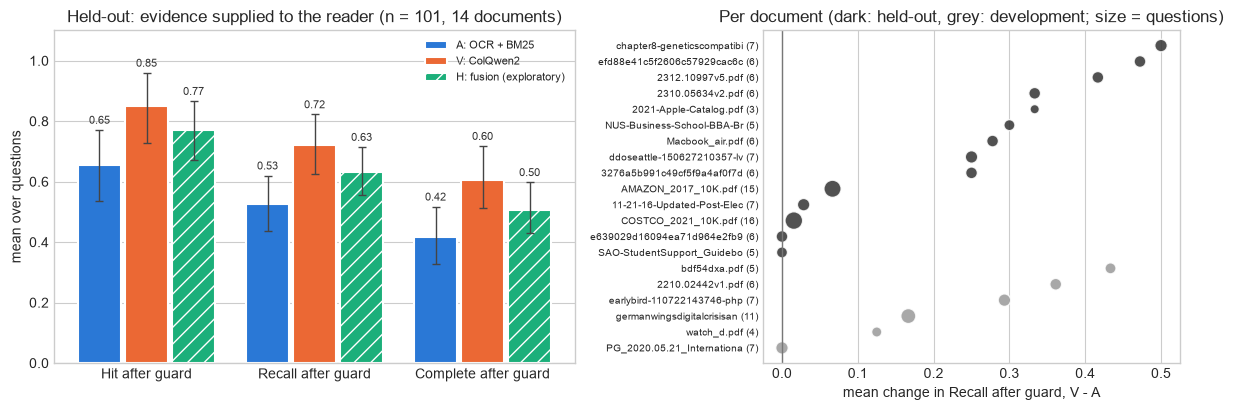

In [27]:
# Figure: (left) evidence that reaches the model, held-out, per arm, with document-cluster 95 % intervals;
# (right) per-document change in Recall_after (V - A), held-out and development.
ARM_COLOR = {"A": "#2a78d6", "V": "#eb6834", "H": "#1baf7a"}  # validated categorical slots 1-3 (light surface)
FIGURE_DIR = E5_DIR / "figures"
FIGURE_DIR.mkdir(exist_ok=True)
after_metrics = [("hit_after", "Hit"), ("recall_after", "Recall"), ("complete_after", "Complete")]
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
width = 0.26
for i, arm in enumerate(ARMS):
    for j, (metric, _) in enumerate(after_metrics):
        mean = held_frame[f"{metric}_{arm}"].mean()
        low, high = cluster_bootstrap(held_frame, f"{metric}_{arm}")
        x = j + (i - 1) * (width + 0.02)
        left.bar(x, mean, width, color=ARM_COLOR[arm], hatch="//" if arm == "H" else None, edgecolor="white", linewidth=1.5,
                 label=ARM_LABEL[arm] if j == 0 else None)
        left.errorbar(x, mean, yerr=[[mean - low], [high - mean]], color="#444444", capsize=3, linewidth=1)
        left.text(x, high + 0.02, f"{mean:.2f}", ha="center", fontsize=8, color="#333333")
left.set(xticks=range(len(after_metrics)), xticklabels=[f"{label} after guard" for _, label in after_metrics], ylim=(0, 1.1),
         ylabel="mean over questions", title=f"Held-out: evidence supplied to the reader (n = {len(held_frame)}, {held_frame['doc_id'].nunique()} documents)")
left.legend(fontsize=8, loc="upper right", frameon=False)
left.grid(axis="x", visible=False)

per_doc = per_question.assign(diff=per_question["recall_after_V"] - per_question["recall_after_A"]).groupby(["population", "doc_id"]).agg(
    diff=("diff", "mean"), n=("qid", "size")).reset_index().sort_values(["population", "diff"])
y = np.arange(len(per_doc))
colors = np.where(per_doc["population"] == "held-out", "#333333", "#999999")
right.axvline(0, color="#777777", linewidth=1)
right.scatter(per_doc["diff"], y, s=18 + 9 * per_doc["n"], c=colors, alpha=0.85, edgecolors="white", linewidths=1)
right.set_yticks(y, [f"{d[:26]} ({n})" for d, n in zip(per_doc["doc_id"], per_doc["n"])], fontsize=7)
right.set(xlabel="mean change in Recall after guard, V - A", title="Per document (dark: held-out, grey: development; size = questions)")
right.grid(axis="y", visible=False)
plt.tight_layout()
fig.savefig(FIGURE_DIR / "e5_evidence_after_guard.png", dpi=150, bbox_inches="tight")
plt.show()

In [28]:
# Where does any difference sit? Held-out, by evidence source, document type and OCR. Descriptive only: groups overlap
# (a question can have several sources) and are small. Under 10 questions, only counts of better / worse / same are shown.
def group_rows(frame, key):
    rows = []
    for value, group in frame.groupby(key):
        diff = group["recall_after_V"] - group["recall_after_A"]
        row = {"group": f"{key}: {value}", "questions": len(group), "V better": int((diff > 0).sum()), "V worse": int((diff < 0).sum()),
               "same": int((diff == 0).sum())}
        if len(group) >= 10:
            row.update({"Recall_after A": round(group["recall_after_A"].mean(), 3), "Recall_after V": round(group["recall_after_V"].mean(), 3),
                        "delta": round(diff.mean(), 3)})
        rows.append(row)
    return rows


breakdown_frame = held_frame.explode("evidence_sources")
breakdown = pd.DataFrame(group_rows(breakdown_frame, "evidence_sources") + group_rows(held_frame, "doc_type")
                         + group_rows(held_frame.assign(ocr=np.where(held_frame["evidence_on_ocr_page"], "evidence on an OCR'd page", "born-digital evidence")), "ocr")
                         + group_rows(held_frame.assign(pages=np.where(held_frame["n_evidence"] > 1, "multi-page", "single page")), "pages"))
breakdown.astype(object).fillna("")

,group,questions,V better,V worse,same,Recall_after A,Recall_after V,delta
0,evidence_sources: Chart,12,3,0,9,0.767,0.95,0.183
1,evidence_sources: Figure,25,15,1,9,0.4,0.85,0.45
2,evidence_sources: Generalized-text (Layout),14,7,0,7,0.452,0.756,0.304
3,evidence_sources: Pure-text (Plain-text),32,6,5,21,0.661,0.677,0.016
4,evidence_sources: Table,36,5,1,30,0.451,0.528,0.076
5,doc_type: Academic paper,12,6,1,5,0.375,0.75,0.375
6,doc_type: Administration/Industry file,12,5,2,5,0.625,0.75,0.125
7,doc_type: Brochure,8,3,0,5,,,
8,doc_type: Financial report,31,3,1,27,0.508,0.548,0.04
9,doc_type: Guidebook,11,2,1,8,0.591,0.742,0.152


### Results

**Primary endpoint (held-out: 101 questions, 14 documents).** The verdict is **`visual_improves_evidence`**: all four pre-registered conditions hold.

| after the context guard, held-out | A: OCR + BM25 | V: ColQwen2 | V − A (document-cluster 95 %) |
|---|---:|---:|---:|
| **Recall (primary)** | **0.526** | **0.721** | **+0.195 [+0.110, +0.309]** |
| Hit: any evidence supplied | 66/101 | 86/101 | +0.198 [+0.102, +0.325] |
| Complete: all evidence supplied | 42/101 | 61/101 | +0.188 [+0.099, +0.308] |
| questions with more / less evidence under V | | | 31 / 6 (64 same) |

**Tests.**

- **Sign-flip p = 0.0005, the smallest value this test can give.** It is exact and works at the document level. Two documents show no difference, so it runs over the other 12, and all 12 favour V.
- **McNemar.** For Hit, 23 questions gain evidence under V and 3 lose it, p < 0.001. This test ignores clustering.
- **Leave-one-document-out.** Dropping any single document leaves the gain between +0.172 and +0.229.
- **Per document.** V is better on 12 of the 14 held-out documents, equal on 2, and worse on none.

**Every ranking metric agrees.** Before the guard:

- Recall@5: 0.556 → 0.762;
- MRR: 0.539 → 0.770;
- nDCG@5: 0.482 → 0.709;
- median rank of the best evidence page: 2 → 1;
- questions with no evidence page in the top 5: 32 → 12.

**Development set (exploratory, 40 questions; earlier experiments chose settings on it).** The same direction, with a similar size:

- Recall after the guard: 0.608 → 0.826;
- evidence supplied: 29/40 → 38/40;
- all evidence supplied: 20/40 → 28/40.

Arm A reproduces notebook 01 and E4 exactly.

**Fusion (H, exploratory).** Fusion sits between the two arms: 0.631 after the guard. It is **worse than ColQwen2 alone** (−0.090 [−0.183, −0.026]). With an untuned $k = 60$, BM25's ranks pull good visual ranks down more often than they rescue them.

**Where the gain sits** (descriptive; overlapping groups, 3–36 questions each):

- **Large:**
  - evidence in a **figure** (25 questions, 0.40 → 0.85);
  - **layout** text (14 questions, 0.45 → 0.76);
  - evidence on **OCR'd pages** (22 questions, 0.49 → 0.85).
- **Small:**
  - **plain text** (32 questions, 0.66 → 0.68; 6 better, 5 worse);
  - **tables** (36 questions, 0.45 → 0.53);
  - **financial 10-Ks** (31 questions, 0.51 → 0.55).
- **Not only scans:** born-digital evidence also gains (79 questions, 0.54 → 0.68), and so do the two academic papers (+0.33, +0.42).

## 8. Failure analysis

Each question is put in one **mechanical** category by comparing how many evidence pages each arm supplies. Questions where the context guard drops a retrieved evidence page are counted separately. The categories are observed facts about pages.

Explanations of *why* a retriever ranked a page where it did are hypotheses. A page containing a chart does not show that the chart drove the ranking, so the examples below show the pages and scores and leave the causal reading open.

In [29]:
def category(row):
    a, v, n = row["evidence_supplied_A"], row["evidence_supplied_V"], row["n_evidence"]
    if v > a:
        return "V supplies more evidence" + (" (A none)" if a == 0 else "")
    if a > v:
        return "A supplies more evidence" + (" (V none)" if v == 0 else "")
    return "both supply none" if a == 0 else ("both complete" if a == n else "both partial, same count")


per_question["category"] = per_question.apply(category, axis=1)
display(pd.crosstab(per_question["category"], per_question["population"], margins=True))

guard_losses = pd.DataFrame({
    (population, ARM_LABEL[arm]): {
        "evidence pages retrieved in top 5": int((frame[f"recall@5_{arm}"] * frame["n_evidence"]).round().sum()),
        "evidence pages supplied": int(frame[f"evidence_supplied_{arm}"].sum()),
        "evidence pages lost to the guard": int(frame[f"evidence_lost_to_guard_{arm}"].sum()),
        "questions losing their only hit to the guard": int(((frame[f"hit@5_{arm}"] == 1) & (frame[f"hit_after_{arm}"] == 0)).sum()),
        "questions with no evidence in the top 5": int((frame[f"hit@5_{arm}"] == 0).sum()),
    }
    for population, frame in per_question.groupby("population") for arm in ARMS})
display(guard_losses)
first_ranks = per_question.groupby("population")[["first_rank_A", "first_rank_V"]].describe().T.round(1)
print("Rank of the best evidence page in the full ranking:")
display(first_ranks.loc[(slice(None), ["mean", "25%", "50%", "75%", "max"]), :])

population,development,held-out,All
category,,,
A supplies more evidence,0,3,3
A supplies more evidence (V none),1,3,4
V supplies more evidence,4,8,12
V supplies more evidence (A none),10,23,33
both complete,20,38,58
"both partial, same count",4,14,18
both supply none,1,12,13
All,40,101,141


development                                          held-out                                    
                                             A: OCR + BM25 V: ColQwen2 H: fusion (exploratory) A: OCR + BM25 V: ColQwen2 H: fusion (exploratory)
evidence pages retrieved in top 5                       39          59                      48            82         117                     106
evidence pages supplied                                 33          53                      40            75         107                      94
evidence pages lost to the guard                         6           6                       8             7          10                      12
questions losing their only hit to the guard             3           0                       3             3           3                       2
questions with no evidence in the top 5                  8           2                       4            32          12                      21

Rank of the best evidence page in the full ranking:


population         development  held-out
first_rank_A mean          3.9       6.9
             25%           1.0       1.0
             50%           2.0       2.0
             75%           5.0       8.0
             max          22.0      68.0
first_rank_V mean          2.1       4.0
             25%           1.0       1.0
             50%           1.0       1.0
             75%           2.0       2.0
             max          15.0      46.0


### BM25 fails, ColQwen2 succeeds — mmlb-0048 (held-out; 23 held-out, 10 development)
Q: How many hand drawn cartoons are included in the slides to illustrate the idea?
Reference: 4 | evidence [17, 25, 40, 51] (Figure) | ddoseattle-150627210357-lva1-app6891_95., 63 pages
  A: OCR + BM25  top 5: 4 (6.96), 22 (6.59), 62 (5.81), 12 (4.85), 44 (4.59) | supplied [4, 22, 62, 12] | best evidence rank 9
  V: ColQwen2    top 5: 17* (15.59), 25* (15.57), 51* (14.77), 40* (13.87), 23 (13.47) | supplied [17, 25, 51, 40] | best evidence rank 1


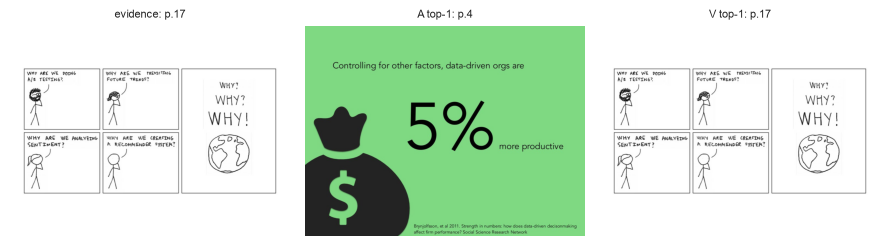


### ColQwen2 fails, BM25 succeeds — mmlb-0578 (held-out; 3 held-out, 1 development)
Q: What date is mentioned at the beginning of page(1)? Format the date as YYYY-MM-DD
Reference: 2003-10-07 | evidence [5] (Pure-text (Plain-text)) | e639029d16094ea71d964e2fb953952b.pdf, 20 pages
  A: OCR + BM25  top 5: 3 (6.85), 11 (5.02), 19 (3.89), 5* (3.88), 20 (3.65) | supplied [3, 11, 19, 5] | best evidence rank 4
  V: ColQwen2    top 5: 1 (20.56), 14 (20.31), 2 (20.22), 17 (20.15), 6 (20.10) | supplied [1, 14, 2, 17] | best evidence rank 9


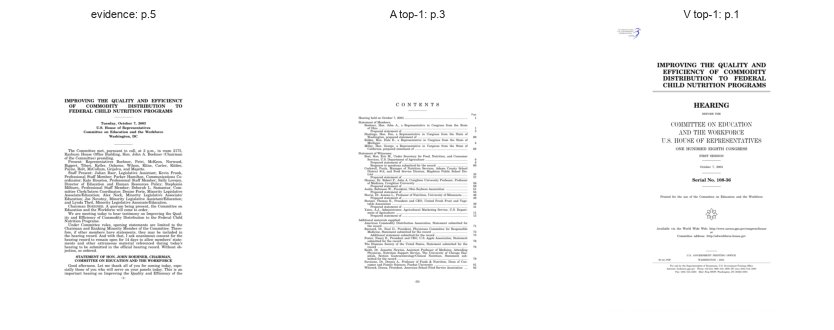


### both fail — mmlb-0078 (held-out; 12 held-out, 1 development)
Q: What is the paper's full title that proposes the method that has a retrieval granularity of phrase?
Reference: Copy is all you need.  | evidence [6, 17] (Table, Pure-text (Plain-text)) | 2312.10997v5.pdf, 21 pages
  A: OCR + BM25  top 5: 4 (8.14), 8 (8.00), 2 (7.52), 16 (7.50), 1 (7.37) | supplied [4, 8, 2, 16] | best evidence rank 8
  V: ColQwen2    top 5: 8 (17.06), 2 (16.89), 1 (16.33), 11 (16.20), 6* (16.18) | supplied [8, 2, 1, 11] | best evidence rank 5


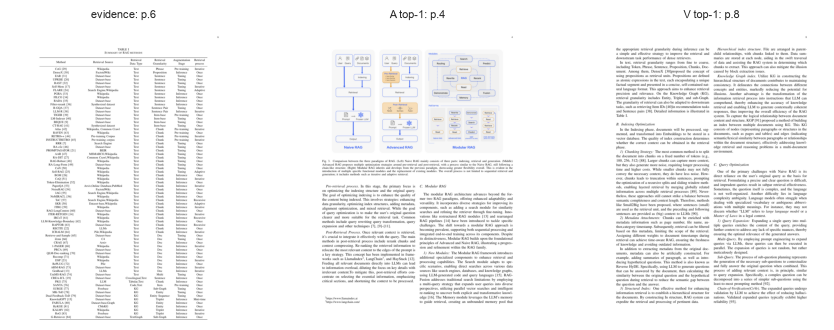


### both partial — mmlb-0046 (held-out; 18 held-out, 5 development)
Q: Which Youtube does the slides use to show the consequce of blindly following data?
Reference: Girl crash into lake following bad GPS direction | evidence [49, 50] (Figure, Generalized-text (Layout)) | ddoseattle-150627210357-lva1-app6891_95., 63 pages
  A: OCR + BM25  top 5: 49* (9.42), 39 (6.88), 46 (6.83), 62 (6.26), 7 (6.08) | supplied [49, 39, 46, 62] | best evidence rank 1
  V: ColQwen2    top 5: 49* (15.82), 25 (14.30), 39 (14.15), 52 (14.00), 51 (13.72) | supplied [49, 25, 39, 52] | best evidence rank 1


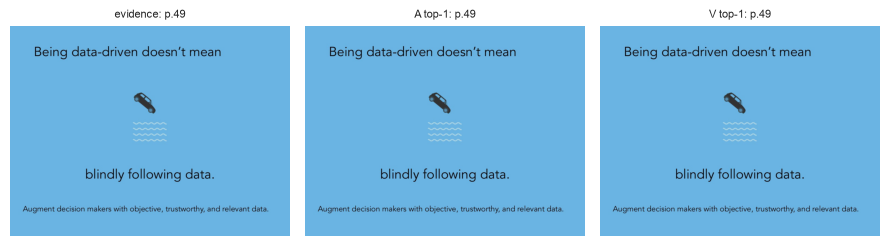


### evidence retrieved, dropped by the guard — mmlb-0049 (held-out; 12 held-out, 9 development)
Q: According to the slides, what are the things that a data-driven person has?
Reference: ['a goals first approach', 'an objective, inquisitive culture', 'a visible, clear articulated strategy', 'strong data leadership', 'a strong testing culture', 'an open, sharing culture', 'a self-service culture', 'a broad data literacy'] | evidence [21, 26, 36, 39, 42, 43, 44, 45] (Generalized-text (Layout), Figure) | ddoseattle-150627210357-lva1-app6891_95., 63 pages
  A: OCR + BM25  top 5: 62 (9.46), 63 (8.70), 12 (7.72), 22 (7.55), 43* (7.41) | supplied [62, 63, 12, 22] | best evidence rank 5
  V: ColQwen2    top 5: 39* (19.80), 11 (19.24), 8 (19.15), 45* (19.04), 21* (19.01) | supplied [39, 11, 8, 45] | best evidence rank 1


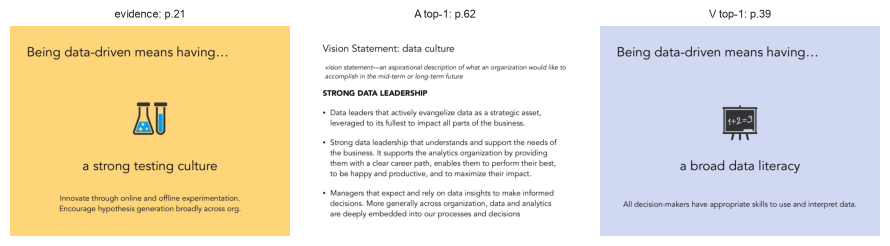

* = annotated evidence page; scores are BM25 (A) and MaxSim (V), not comparable across arms.


In [30]:
# Representative held-out cases, chosen by a fixed rule (the first question id in each case type; development if the
# held-out set has none): question, evidence pages, both top 5 lists with scores, what was supplied, and page images.
case_rules = {
    "BM25 fails, ColQwen2 succeeds": lambda f: (f["hit_after_A"] == 0) & (f["hit_after_V"] == 1),
    "ColQwen2 fails, BM25 succeeds": lambda f: (f["hit_after_V"] == 0) & (f["hit_after_A"] == 1),
    "both fail": lambda f: (f["hit_after_A"] == 0) & (f["hit_after_V"] == 0),
    "both partial": lambda f: f["recall_after_A"].between(0, 1, inclusive="neither") & f["recall_after_V"].between(0, 1, inclusive="neither"),
    "evidence retrieved, dropped by the guard": lambda f: (f["evidence_lost_to_guard_V"] > 0) | (f["evidence_lost_to_guard_A"] > 0),
}
image_of = all_pages.set_index(["doc_id", "page"])["image_path"]
case_counts = {}
for name, rule in case_rules.items():
    matches = {pop: per_question[(per_question["population"] == pop) & rule(per_question)].sort_values("qid") for pop in ("held-out", "development")}
    case_counts[name] = {pop: len(m) for pop, m in matches.items()}
    source = "held-out" if len(matches["held-out"]) else "development"
    if not len(matches[source]):
        print(f"\n### {name}: no question in either population")
        continue
    case = matches[source].iloc[0]
    qid = case["qid"]
    print(f"\n### {name} — {qid} ({source}; {case_counts[name]['held-out']} held-out, {case_counts[name]['development']} development)")
    print(f"Q: {question_text[qid]}\nReference: {bench.set_index('qid').loc[qid, 'answer']} | evidence {[int(p) for p in case['evidence_pages']]} "
          f"({', '.join(case['evidence_sources'])}) | {case['doc_id'][:40]}, {case['page_count']} pages")
    for arm in ("A", "V"):
        top = RANKINGS[arm][qid][:5]
        marks = ", ".join(f"{p}{'*' if p in case['evidence_pages'] else ''} ({s:.2f})" for p, s in top)
        print(f"  {ARM_LABEL[arm]:<14} top 5: {marks} | supplied {SUPPLIED[arm][qid]} | best evidence rank {case[f'first_rank_{arm}']}")
    shown = [("evidence", case["evidence_pages"][0]), ("A top-1", RANKINGS["A"][qid][0][0]), ("V top-1", RANKINGS["V"][qid][0][0])]
    fig, axes = plt.subplots(1, 3, figsize=(9, 3.4))
    for ax, (label, page) in zip(axes, shown):
        ax.imshow(plt.imread(PROJECT_ROOT / image_of[(case["doc_id"], page)]))
        ax.set_title(f"{label}: p.{page}", fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
print("* = annotated evidence page; scores are BM25 (A) and MaxSim (V), not comparable across arms.")

**What the cases show (observations first, then hypotheses).**

**Observed.** These categories are mechanical counts over the 101 held-out questions:

- **V supplies more evidence: 31.** In 23 of them, A supplies none.
- **A supplies more evidence: 6.** In 3 of them, V supplies none.
- **Both supply none: 12.**
- **Both complete: 38.**
- **Both partial, same count: 14.**

**Example 1: BM25 fails, ColQwen2 succeeds** (`mmlb-0048`, "How many hand drawn cartoons…").

- ColQwen2 ranks all four annotated cartoon slides 1–4.
- BM25's best evidence rank is 9: on OCR text, its top pages are slides that share words with the question.
- *Hypothesis:* the cartoons' visual style is what matches "hand drawn cartoons", a property that OCR text does not carry. The example is consistent with that; it does not prove it.

**Example 2: ColQwen2 fails, BM25 succeeds** (`mmlb-0578`, "What date is mentioned at the beginning of page(1)?").

- The evidence is physical page 5, which is printed "(1)".
- ColQwen2 ranks physical page 1 first and page 5 only 9th, and the scores of its top 5 lie within 0.5 of each other.
- BM25 ranks page 5 fourth, which is enough to supply it.
- *Hypothesis:* questions that cite **printed page labels** reward neither method. This is the failure notebook 01 recorded for BM25.

**Example 3: both fail** (`mmlb-0078`, 12 held-out questions in this category).

- A paper-title question whose evidence is a table (p. 6) and a text page (p. 17).
- ColQwen2 ranks evidence 5th, so the guard drops it; BM25 ranks it 8th.
- **The category is dominated by the two 10-Ks.** 9 of the 12 are on the Amazon or Costco 10-K, and 7 of those ask for a derived figure: EBITDA, return on assets, effective tax rate, debt to EBITDA.
  - Their evidence is a statement table that never names the ratio. Ten of the 12 cite a table, and 8 need two or three pages.
  - Neither retriever can match "return on assets" to a balance sheet. That needs the question to be decomposed into its inputs, which is not a retrieval-representation problem.

**The guard still costs evidence.** It drops retrieved evidence pages under both arms (A 7, V 10). Three questions per arm lose their only hit at rank 5 (`mmlb-0049` keeps 2 of its 8 evidence pages under V).

- *Why ColQwen2 loses more:* it ranks more evidence into the top 5, so more lands in 5th place, where the guard cuts. Once the guard keeps 3–4 pages, rank 5 is wasted for both arms.

**Multi-page questions** (46 of 101) remain the hardest: recall after the guard is 0.37 → 0.52. No top-4 list can cover an evidence set of 5–8 pages, whichever retriever produces it.

## 9. Computational and operational cost

Times come from the encoding log written while the pages were encoded. Encoding happens once per page, and cached runs only read the log.

Every figure is for **this machine** (Apple M1, 8 GB unified memory, MPS, bf16). A GPU server would be one to two orders of magnitude faster: the ColPali paper reports 0.39 s per page on an L4. Treat the numbers as the cost of running E5 here, not as a property of the method.

In [31]:
encoding_log = pd.read_csv(ENCODING_LOG)
encoding_log = encoding_log[encoding_log["key"].isin(set(page_jobs["sha256"]) | {query_key(q) for q in retrieval_questions["question"]})]
peaks_path = E5_DIR / "encoding_peaks.json"
if PASS_PEAKS:  # this execution encoded something: keep its peaks with the log (merged by pass)
    saved = json.loads(peaks_path.read_text()) if peaks_path.is_file() else {}
    atomic_write_bytes(peaks_path, json.dumps({**saved, **{p: {**v, "session": SESSION} for p, v in PASS_PEAKS.items()}}, indent=1).encode())
PEAKS = json.loads(peaks_path.read_text()) if peaks_path.is_file() else {}
storage_bytes = sum(page_cache_path(s).stat().st_size for s in page_jobs["sha256"])
tokens = np.array([PAGE_EMB[s].shape[0] for s in page_jobs["sha256"]])
by_pass = encoding_log.groupby("pass")["seconds"]
cost = {
    "pages encoded (distinct images)": len(page_jobs),
    "vision pass, s per page (median / total h)": f"{by_pass.median().get('vision', np.nan):.1f} / {by_pass.sum().get('vision', 0) / 3600:.2f}",
    "language pass, s per page (median / total h)": f"{by_pass.median().get('language', np.nan):.1f} / {by_pass.sum().get('language', 0) / 3600:.2f}",
    "indexing, s per page (two passes, median)": f"{by_pass.median().get('vision', 0) + by_pass.median().get('language', 0):.1f}",
    "query encoding, s per query (median)": f"{by_pass.median().get('query', np.nan):.2f}",
    "MaxSim scoring, ms per question (all pages of its PDF)": f"{1e3 * visual_score_seconds:.1f}",
    "model load, s (vision pass / language pass)": " / ".join(f"{encoding_log.loc[encoding_log['pass'] == p, 'load_seconds'].max():.0f}" for p in ("vision", "language")),
    # Peaks are kept only for passes whose kernel survived to this cell (the first run's vision pass ended with its session).
    "peak process RSS, GB (vision / language)": " / ".join(f"{PEAKS.get(p, {}).get('rss_gb', np.nan):.2f}" for p in ("vision", "language")),
    "peak MPS driver memory, GB (vision / language)": " / ".join(f"{PEAKS.get(p, {}).get('mps_driver_gb', np.nan):.2f}" for p in ("vision", "language")),
    "vectors per page (mean, min-max)": f"{tokens.mean():.0f} ({tokens.min()}-{tokens.max()})",
    "embedding storage (bf16 safetensors)": f"{storage_bytes / 1e6:.0f} MB, {storage_bytes / len(page_jobs) / 1e3:.0f} KB per page",
    "model weights on disk": f"{MODEL['weights_bytes'] / 1e9:.2f} GB",
    "BM25: index, ms per page / query, ms": f"{1e3 * bm25_index_seconds / len(all_pages):.2f} / {1e3 * bm25_query_seconds:.2f}",
    "baseline text: held-out extraction incl. OCR, s per page": f"{text_seconds / len(held_pages):.2f} (OCR on {int(held_pages['ocr_used'].sum())} of {len(held_pages)} pages)",
}
COST = cost
pd.Series(cost, name="value").to_frame()

,value
pages encoded (distinct images),837
"vision pass, s per page (median / total h)",9.8 / 2.31
"language pass, s per page (median / total h)",2.7 / 0.63
"indexing, s per page (two passes, median)",12.5
"query encoding, s per query (median)",0.16
"MaxSim scoring, ms per question (all pages of its PDF)",3.6
"model load, s (vision pass / language pass)",5 / 13
"peak process RSS, GB (vision / language)",nan / 0.24
"peak MPS driver memory, GB (vision / language)",nan / 3.33
"vectors per page (mean, min-max)",755 (731-779)


## 10. Reproducibility: save, compare with the frozen result, validate

Outputs go to `data/processed/mmlongbench_doc/e5/`, which is git-ignored and regenerable:

- `rankings.parquet`: every arm's full ranking with scores, 175 questions;
- `per_question.csv`;
- `summary.json`;
- the figure.

The frozen copy in `experiments/frozen/e5/` is committed. When it exists, this section verifies its checksums and requires the regenerated tables to equal it. It contains no page images, question text or embeddings.

In [32]:
def jsonable(value):
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return jsonable(float(value))
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, float):
        return None if value != value else round(value, 6)  # NaN ("not applicable") -> JSON null
    if isinstance(value, dict):
        return {str(k): jsonable(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [jsonable(v) for v in value]
    return value


rankings_table = pd.DataFrame([{"qid": qid, "population": retrieval_questions.set_index("qid").loc[qid, "population"], "doc_id": doc_of[qid],
                                "arm": arm, "pages": [p for p, _ in ranking], "scores": [round(s, 6) for _, s in ranking]}
                               for arm in ARMS for qid, ranking in RANKINGS[arm].items()])
rankings_table.to_parquet(E5_DIR / "rankings.parquet", index=False)
per_question_out = per_question.copy()
for column in [c for c in per_question_out.columns if per_question_out[c].map(lambda v: isinstance(v, list)).any()]:
    per_question_out[column] = per_question_out[column].map(lambda v: json.dumps(jsonable(list(v))))  # NumPy ints -> int
float_columns = per_question_out.select_dtypes("float").columns
per_question_out[float_columns] = per_question_out[float_columns].round(6)
per_question_out.to_csv(E5_DIR / "per_question.csv", index=False)

RESULTS = {
    "spec_id": SPEC["spec_id"], "spec_freeze_commit": SPEC_FREEZE_COMMIT,
    "model": {"repo": MODEL["repo"], "revision": MODEL["revision"], "encoder_config_hash": CONFIG_HASH},
    "populations": {pop: {"questions": int((per_question["population"] == pop).sum()), "documents": int(per_question.loc[per_question["population"] == pop, "doc_id"].nunique())}
                    for pop in ("development", "held-out")},
    "summary": {pop: {arm: {m: per_question.loc[per_question["population"] == pop, f"{m}_{arm}"].mean() for m in METRICS} for arm in ARMS}
                for pop in ("development", "held-out")},
    "paired": paired_results.drop(columns=[c for c in ("A", "V", "H") if c in paired_results]).to_dict(orient="records"),
    "decision": {"verdict": VERDICT, "recommendation": RECOMMENDATION, "conditions": conditions,
                 "more_evidence_V": more_evidence, "less_evidence_V": less_evidence},
    "categories": pd.crosstab(per_question["category"], per_question["population"]).to_dict(),
    "spot_check": {q: list(v) for q, v in SPOT_CHECK_LABELS.items()},
    "regression": {"dev_recall@5_A": dev_frame["recall@5_A"].mean(), "dev_hit@5_A": dev_frame["hit@5_A"].mean(),
                   "dev_hit_after_A_count": int(dev_frame["hit_after_A"].sum())},
}
RESULTS = jsonable(RESULTS)
(E5_DIR / "summary.json").write_text(json.dumps(RESULTS, indent=1, sort_keys=True))
# Run context, kept apart from the results so that the results file is identical across executions.
(E5_DIR / "run_context.json").write_text(json.dumps(jsonable({"environment": ENVIRONMENT, "encoder_config": ENCODER_CONFIG, "cost": COST,
                                                              "peaks": PEAKS, "single_pass_check": SINGLE_PASS_CHECK}), indent=1, default=str))
print(f"Saved rankings.parquet ({len(rankings_table)} rows), per_question.csv ({len(per_question_out)} rows), summary.json, "
      f"run_context.json and figures/ to {E5_DIR.relative_to(PROJECT_ROOT)}")

Saved rankings.parquet (525 rows), per_question.csv (141 rows), summary.json, run_context.json and figures/ to data/processed/mmlongbench_doc/e5


In [33]:
# Regression against the frozen E5 result, once it exists: checksums, then the regenerated tables must equal the frozen ones.
FROZEN_FILES = ["summary.json", "per_question.csv", "rankings.parquet"]
if FROZEN_E5_DIR.is_dir():
    for line in (FROZEN_E5_DIR / "SHA256SUMS").read_text().splitlines():
        digest, name = line.split(maxsplit=1)
        assert sha256_file(FROZEN_E5_DIR / name.strip()) == digest, f"frozen file changed: {name}"
    assert json.loads((FROZEN_E5_DIR / "tables" / "summary.json").read_text()) == RESULTS, "summary differs from the frozen result"
    assert (FROZEN_E5_DIR / "tables" / "per_question.csv").read_bytes() == (E5_DIR / "per_question.csv").read_bytes()
    frozen_rankings = pd.read_parquet(FROZEN_E5_DIR / "tables" / "rankings.parquet")
    assert frozen_rankings.map(lambda v: v.tolist() if hasattr(v, "tolist") else v).equals(
        rankings_table.map(lambda v: v.tolist() if hasattr(v, "tolist") else v)), "rankings differ from the frozen result"
    print(f"Frozen E5 result verified: SHA256SUMS hold; summary, per-question table and all {len(rankings_table)} rankings regenerate exactly.")
else:
    print("No frozen E5 result yet (experiments/frozen/e5/ is created after the first complete execution).")

Frozen E5 result verified: SHA256SUMS hold; summary, per-question table and all 525 rankings regenerate exactly.


### Validation

The checks below cover the experiment's mechanics:

- page alignment, and the guard's behaviour;
- denominators and metric ranges;
- the regression references;
- cache integrity and determinism;
- leakage;
- the annotation spot check.

They show that the comparison was computed as specified. They do not show that the annotations are right, that the sample represents other documents, or that more evidence would yield more correct answers.

In [34]:
# 1. Page alignment: every ranking is a permutation of its PDF's 1-based pages (checked in section 5); evidence pages lie in the PDF.
assert all(1 <= p <= row.page_count for row in per_question.itertuples() for p in row.evidence_pages)
# 2. The guard only truncates: supplied + dropped = top 5, supplied is a ranked prefix, and the page budget per question
#    depends only on page sizes (so A and V receive the same number of pages in a document with one page size).
for arm in ARMS:
    assert all(SUPPLIED[arm][q] + DROPPED[arm][q] == [p for p, _ in RANKINGS[arm][q][:5]] for q in retrieval_questions["qid"])
uniform_docs = set(mixed[mixed == 1].index)
assert all(len(SUPPLIED["A"][q]) == len(SUPPLIED["V"][q]) for q in retrieval_questions["qid"] if doc_of[q] in uniform_docs)
# 3. Denominators and ranges: 40 development questions (notebook 01) and the held-out evidence population.
assert (per_question["population"] == "development").sum() == 40 and (per_question["population"] == "held-out").sum() == len(held_pop)
for arm in ARMS:
    after = per_question[[f"hit_after_{arm}", f"recall_after_{arm}", f"complete_after_{arm}"]]
    assert ((after >= 0) & (after <= 1)).all().all()
    assert (after[f"hit_after_{arm}"] >= after[f"recall_after_{arm}"] - 1e-12).all() and (after[f"recall_after_{arm}"] >= after[f"complete_after_{arm}"]).all()
    assert (per_question[f"recall_after_{arm}"] <= per_question[f"recall@5_{arm}"] + 1e-12).all()
    assert all(per_question[f"recall@{k}_{arm}"].le(per_question[f"recall@{k2}_{arm}"] + 1e-12).all() for k, k2 in zip([1, 3, 4], [3, 4, 5]))
# 4. Regression references (frozen E0/E4 and notebook 01).
regression = RESULTS["regression"]
assert round(regression["dev_recall@5_A"], 3) == 0.689 and regression["dev_hit@5_A"] == 0.8 and regression["dev_hit_after_A_count"] == 29
# 5. Cache integrity: the cache's configuration file equals this run's; every embedding is keyed by an existing page image,
#    has 128-d unit rows and as many rows as the processor's sequence for that page (checked on the demo pages).
assert json.loads((CACHE_DIR / "config.json").read_text()) == ENCODER_CONFIG
cached_keys = {p.stem for p in (CACHE_DIR / "pages").glob("*.safetensors")}
assert set(page_jobs["sha256"]) <= cached_keys
assert all(e.shape[1] == 128 and torch.allclose(e.norm(dim=1), torch.ones(e.shape[0]), atol=1e-2) for e in PAGE_EMB.values())
assert all(PAGE_EMB[page_sha[(r.doc_id, r.page)]].shape[0] == int(processor(images=[load_page_image(r.image_path)], return_tensors="pt")["input_ids"].shape[1])
           for r in demo_rows.itertuples())
# 6. Determinism: rankings recomputed identically (section 5); two-pass = single-pass bitwise (section 4) unless skipped.
assert SINGLE_PASS_CHECK["run"] is False or all(r["bitwise equal to cache"] for r in SINGLE_PASS_CHECK["results"])
# 7. Spot check complete: every sampled question labelled, labels from the allowed set.
assert set(SPOT_CHECK_LABELS) == set(spot_qids) and all(label in {"supported", "partly", "not supported"} for label, _ in SPOT_CHECK_LABELS.values())
# 8. Failure case / limitation: evidence retrieved in the top 5 but never shown to the reader, per arm.
lost = {arm: int(((per_question[f"hit@5_{arm}"] == 1) & (per_question[f"hit_after_{arm}"] == 0)).sum()) for arm in ARMS}
print(f"All validation checks passed. Limitation in view: questions whose only retrieved evidence the guard drops: {lost}.")

All validation checks passed. Limitation in view: questions whose only retrieved evidence the guard drops: {'A': 6, 'V': 3, 'H': 5}.


## Interpretation and decision

**Answer to the research question.** Under the application's real constraints (3–4 pages at 768 px after the context guard), **ColQwen2 v1.0 supplies substantially more annotated evidence than OCR + BM25**. On 101 held-out questions that no earlier experiment touched, evidence recall rises from 0.53 to 0.72. Questions receiving any evidence rise from 66 to 86.

- **The effect is consistent:** 12 of 14 documents better, none worse, every metric in the same direction, the development set in agreement.
- **The size is well above** the pre-registered 0.05 threshold. The whole interval, [+0.11, +0.31], lies above it.

**Verdict (pre-registered): `visual_improves_evidence` → investigate further with a controlled end-to-end experiment (E6). Do not integrate yet.**

**Why not adopt directly.** E5 measures **evidence availability**, not answers.

- E4 showed that the reader answers only 17/37 questions even with every evidence page, so more evidence is necessary but not sufficient.
- More supplied evidence translates into more correct answers only where the reader can use it.
- Only an answering experiment can measure that, and it needs paid calls.

**Proposed E6** (a separate spec; your approval and budget are needed before any call):

- **Arms.** The application exactly as shipped, with page selection from BM25 (A) or from ColQwen2 (V). Same GPT-4o-mini snapshot, prompt `mmlb-image-v1`, 768-px images, context guard and parameters.
- **Questions.** Paired, on the held-out questions plus the development set.
- **Primary outcome.** Answerable accuracy, V − A, with a document-cluster interval. Also: abstention on unanswerable questions, and citation validity.
- **Cost.** About 2 × 175 requests at ≤ $0.016 each, so roughly $5 at list price, below a ceiling you would set.

**Operational cost of ColQwen2** (if E6 justifies it):

- **Indexing.** On this fanless M1 with 8 GB, indexing took 12.5 s per page (9.8 s vision + 2.7 s language model), and needed the two-pass workaround and about 4.4 GB of weights. That is roughly 10 minutes for a 50-page PDF, against 0.1 s per page for text extraction with OCR plus BM25.
- **Queries.** They are cheap: 0.16 s to encode, 3 ms to score a 50-page document.
- **Storage.** 193 KB per page (162 MB for 837 pages).
- **In practice.** Indexing belongs at upload time, or on a GPU. A server GPU is reported at about 0.4 s per page.

### Limitations

1. **Sample.** 101 held-out questions in 14 documents, two per document type. Long documents (over 100 pages) were excluded by design, and per-group results rest on 3–36 questions.
2. **Possible training overlap.** ColQwen2 was trained on DocVQA, InfoVQA, TAT-DQA, arXivQA and web PDFs. Whether some held-out pages overlap that data cannot be checked here; an overlap would favour V.
3. **Annotations.** Each question has a single set of annotated evidence pages, and the spot check found 6/8 supported and 2/8 partly supported. A page that also contains the answer but is not annotated counts as a miss for both arms.
4. **One visual model, one configuration.** ColPali v1.3, ColQwen2.5 and other resolutions are untested. The baseline BM25 is untuned, which matches the shipped application.
5. **Evidence is not accuracy.** See the decision above.
6. **Lost measurements.** Peak memory of the vision pass was lost when the first run's session ended. The pre-freeze probe measured 2.19 GB of GPU memory for the vision tower.

### Next steps

1. **E6, end to end** (needs approval): as above.
2. **Context guard.** Rank-5 evidence is dropped for both arms. The 400-token output reservation decides it on 4:3 pages (notebook 03 §16). A smaller reservation or a 4-page top-k is a separate, cheap offline test.
3. **Hard questions.** The cases neither arm solves are mostly derived financial figures (EBITDA, ratios) whose inputs sit in statement tables that never name them (7 of 12), plus multi-page evidence sets and questions that cite printed page labels. These are question-understanding problems (decomposing a question into the quantities it needs), not image retrieval problems.